# 03 — EDA và trực quan hóa dữ liệu NYC 311, 2022–2025

Notebook này là bản **final scope** cho báo cáo. Mục tiêu là đi từ chỉ số tổng hợp sang các khác biệt quan trọng theo loại phản ánh, thời gian, không gian và cơ quan tiếp nhận.

Các nhóm câu hỏi chính:

1. **WHAT** — Loại phản ánh nào chiếm nhiều yêu cầu và loại nào đóng góp vào biến động 2022→2025?
2. **WHEN** — Mẫu theo tháng, thứ và giờ có giống nhau giữa các loại phản ánh không?
3. **WHERE** — Kết luận địa lý thay đổi thế nào khi chuẩn hóa theo dân số?
4. **HOW LONG** — Thời gian đóng có lệch phải và khác nhau thế nào giữa các loại phản ánh?
5. **CHANNEL / AGENCY** — Kênh gửi và cơ cấu công việc giữa các agency khác nhau ra sao?

> Các thống kê closure trong notebook được tính lại từ cùng snapshot **08/10/2026 22:21:35**. `closure_hours` được hiểu là thời gian từ `created_date` đến `closed_date` được ghi nhận trên hệ thống, không đồng nghĩa với thời gian khắc phục vật lý ngoài thực tế.

> Bản này **không thêm** benchmark hiệu năng hoặc drill-down descriptor của Noise vào storyline chính vì hai nhánh đó không trực tiếp vá lỗ hổng của các câu hỏi nghiên cứu hiện tại.


In [1]:
from pathlib import Path
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from matplotlib.ticker import FuncFormatter

MILLION_FORMATTER = FuncFormatter(
    lambda x, pos: (
        f"{x / 1_000_000:.1f}M"
        if abs(x) >= 1_000_000
        else (
            f"{x / 1_000:.0f}K"
            if abs(x) >= 1_000
            else f"{x:.0f}"
        )
    )
)

SNAPSHOT_DATE = pd.Timestamp(
    "2026-10-08 22:21:35"
)

print("Pandas:", pd.__version__)
print("NumPy :", np.__version__)
print("Snapshot:", SNAPSHOT_DATE)

Pandas: 3.0.6
NumPy : 2.5.3
Snapshot: 2026-10-08 22:21:35


In [2]:
cwd = Path.cwd()

if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
EXTERNAL_DIR = PROJECT_ROOT / "data" / "external"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
TABLE_DIR = OUTPUT_DIR / "tables"
CHART_DIR = OUTPUT_DIR / "charts"

EXTERNAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)
TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)
CHART_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project root :", PROJECT_ROOT)
print("Processed dir:", PROCESSED_DIR)
print("External dir :", EXTERNAL_DIR)
print("Table dir    :", TABLE_DIR)
print("Chart dir    :", CHART_DIR)

Project root : d:\nyc311_analysis
Processed dir: d:\nyc311_analysis\data\processed
External dir : d:\nyc311_analysis\data\external
Table dir    : d:\nyc311_analysis\outputs\tables
Chart dir    : d:\nyc311_analysis\outputs\charts


In [3]:
processed_files = sorted(
    PROCESSED_DIR.glob(
        "nyc311_*_*_processed.parquet"
    )
)

print(
    "Processed files:",
    len(processed_files)
)

assert len(processed_files) == 48, (
    f"Expected 48 files, "
    f"found {len(processed_files)}"
)

Processed files: 48


In [4]:
YEARLY_FILE = (
    TABLE_DIR
    / "yearly_requests.parquet"
)

COMPLAINT_FILE = (
    TABLE_DIR
    / "complaint_by_year.parquet"
)

MONTHLY_FILE = (
    TABLE_DIR
    / "monthly_requests.parquet"
)

SEASONALITY_FILE = (
    TABLE_DIR
    / "monthly_seasonality.parquet"
)

print("Cache files ready.")

Cache files ready.


In [5]:
FORCE_REBUILD = True

base_cache_exists = (
    YEARLY_FILE.exists()
    and COMPLAINT_FILE.exists()
    and MONTHLY_FILE.exists()
)

if base_cache_exists and not FORCE_REBUILD:

    print("Loading cached EDA tables...")

    yearly_requests = pd.read_parquet(
        YEARLY_FILE
    )

    complaint_by_year = pd.read_parquet(
        COMPLAINT_FILE
    )

    monthly_requests = pd.read_parquet(
        MONTHLY_FILE
    )

else:

    print(
        "Cache not found. "
        "Building EDA tables..."
    )

    yearly_parts = []
    monthly_parts = []
    complaint_parts = []

    for i, file in enumerate(
        processed_files,
        start=1
    ):

        # Chỉ đọc 3 trường thực sự cần
        part = pd.read_parquet(
            file,
            columns=[
                "year",
                "month",
                "complaint_type"
            ]
        )

        # -----------------------
        # Tổng số yêu cầu theo năm
        # -----------------------
        yearly_temp = (
            part
            .groupby("year")
            .size()
            .reset_index(
                name="requests"
            )
        )

        yearly_parts.append(
            yearly_temp
        )

        # -----------------------
        # Tổng số yêu cầu theo tháng
        # -----------------------
        monthly_temp = (
            part
            .groupby(
                ["year", "month"]
            )
            .size()
            .reset_index(
                name="requests"
            )
        )

        monthly_parts.append(
            monthly_temp
        )

        # -----------------------
        # Loại vấn đề theo năm
        # complaint_type
        # = loại vấn đề/yêu cầu
        # -----------------------
        complaint_temp = (
            part
            .dropna(
                subset=[
                    "complaint_type"
                ]
            )
            .groupby(
                [
                    "year",
                    "complaint_type"
                ]
            )
            .size()
            .reset_index(
                name="requests"
            )
        )

        complaint_parts.append(
            complaint_temp
        )

        print(
            f"[{i:02d}/48] "
            f"{file.name}"
        )

    # ==========================
    # YEARLY
    # ==========================
    yearly_requests = (
        pd.concat(
            yearly_parts,
            ignore_index=True
        )
        .groupby(
            "year",
            as_index=False
        )["requests"]
        .sum()
        .sort_values("year")
        .reset_index(drop=True)
    )

    # ==========================
    # MONTHLY
    # ==========================
    monthly_requests = (
        pd.concat(
            monthly_parts,
            ignore_index=True
        )
        .groupby(
            ["year", "month"],
            as_index=False
        )["requests"]
        .sum()
    )

    monthly_requests[
        "year_month"
    ] = pd.to_datetime({
        "year": monthly_requests["year"],
        "month": monthly_requests["month"],
        "day": 1
    })

    monthly_requests[
        "days_in_month"
    ] = (
        monthly_requests[
            "year_month"
        ]
        .dt.days_in_month
    )

    monthly_requests[
        "avg_daily_requests"
    ] = (
        monthly_requests["requests"]
        /
        monthly_requests[
            "days_in_month"
        ]
    )

    monthly_requests = (
        monthly_requests
        .sort_values(
            "year_month"
        )
        .reset_index(drop=True)
    )

    # ==========================
    # COMPLAINT
    # ==========================
    complaint_by_year = (
        pd.concat(
            complaint_parts,
            ignore_index=True
        )
        .groupby(
            [
                "year",
                "complaint_type"
            ],
            as_index=False
        )["requests"]
        .sum()
    )

    # ==========================
    # SAVE CACHE
    # ==========================
    yearly_requests.to_parquet(
        YEARLY_FILE,
        index=False
    )

    complaint_by_year.to_parquet(
        COMPLAINT_FILE,
        index=False
    )

    monthly_requests.to_parquet(
        MONTHLY_FILE,
        index=False
    )

    print(
        "\nEDA base tables saved."
    )

Cache not found. Building EDA tables...
[01/48] nyc311_2022_01_processed.parquet
[02/48] nyc311_2022_02_processed.parquet
[03/48] nyc311_2022_03_processed.parquet
[04/48] nyc311_2022_04_processed.parquet
[05/48] nyc311_2022_05_processed.parquet
[06/48] nyc311_2022_06_processed.parquet
[07/48] nyc311_2022_07_processed.parquet
[08/48] nyc311_2022_08_processed.parquet
[09/48] nyc311_2022_09_processed.parquet
[10/48] nyc311_2022_10_processed.parquet
[11/48] nyc311_2022_11_processed.parquet
[12/48] nyc311_2022_12_processed.parquet
[13/48] nyc311_2023_01_processed.parquet
[14/48] nyc311_2023_02_processed.parquet
[15/48] nyc311_2023_03_processed.parquet
[16/48] nyc311_2023_04_processed.parquet
[17/48] nyc311_2023_05_processed.parquet
[18/48] nyc311_2023_06_processed.parquet
[19/48] nyc311_2023_07_processed.parquet
[20/48] nyc311_2023_08_processed.parquet
[21/48] nyc311_2023_09_processed.parquet
[22/48] nyc311_2023_10_processed.parquet
[23/48] nyc311_2023_11_processed.parquet
[24/48] nyc311_20

In [6]:
print("=== EDA CACHE VALIDATION ===")

print(
    "Years:",
    yearly_requests["year"]
    .tolist()
)

print(
    "Months:",
    len(monthly_requests)
)

print(
    "Total yearly requests:",
    f"{yearly_requests['requests'].sum():,}"
)

print(
    "Total monthly requests:",
    f"{monthly_requests['requests'].sum():,}"
)

print(
    "Complaint rows:",
    len(complaint_by_year)
)

=== EDA CACHE VALIDATION ===
Years: [2022, 2023, 2024, 2025]
Months: 48
Total yearly requests: 13,506,494
Total monthly requests: 13,506,494
Complaint rows: 809


# 1. WHAT — Người dân báo vấn đề gì?

Phần này xem quy mô của từng `complaint_type` và mức thay đổi theo năm. Tỷ trọng được tính trên các request có `complaint_type` hợp lệ.

In [7]:
# ==========================
# WHAT
# Người dân báo vấn đề gì?
# ==========================

complaint_total = (
    complaint_by_year
    .groupby(
        "complaint_type",
        as_index=False
    )["requests"]
    .sum()
    .sort_values(
        "requests",
        ascending=False
    )
    .reset_index(drop=True)
)

complaint_total[
    "share_pct"
] = (
    complaint_total["requests"]
    /
    complaint_total["requests"].sum()
    * 100
).round(2)


# Top 15 loại vấn đề
top15_complaints = (
    complaint_total
    .head(15)
    .copy()
)


# Top 10 theo từng năm
top10_names = (
    complaint_total
    .head(10)[
        "complaint_type"
    ]
    .tolist()
)

top10_yearly = (
    complaint_by_year[
        complaint_by_year[
            "complaint_type"
        ].isin(top10_names)
    ]
    .pivot(
        index="year",
        columns="complaint_type",
        values="requests"
    )
    .reindex(
        columns=top10_names
    )
)


display(
    top15_complaints
)

display(
    top10_yearly
)

,complaint_type,requests,share_pct
0,Illegal Parking,1965737,14.55
1,Noise - Residential,1518147,11.24
2,HEAT/HOT WATER,1074595,7.96
3,Blocked Driveway,665217,4.93
4,Noise - Street/Sidewalk,636557,4.71
5,UNSANITARY CONDITION,453290,3.36
6,Street Condition,284706,2.11
7,Abandoned Vehicle,265652,1.97
8,Noise - Commercial,261197,1.93
9,Water System,260013,1.93


complaint_type,Illegal Parking,Noise - Residential,HEAT/HOT WATER,Blocked Driveway,Noise - Street/Sidewalk,UNSANITARY CONDITION,Street Condition,Abandoned Vehicle,Noise - Commercial,Water System
year,,,,,,,,,,
2022,405943,377049,264390,155872,153058,99248,79125,62477,61143,63164
2023,476809,298453,229509,166430,147449,115439,64093,64946,67749,53627
2024,505728,379296,264750,170192,163001,120854,71158,70326,68347,65773
2025,577257,463349,315946,172723,173049,117749,70330,67903,63958,77449


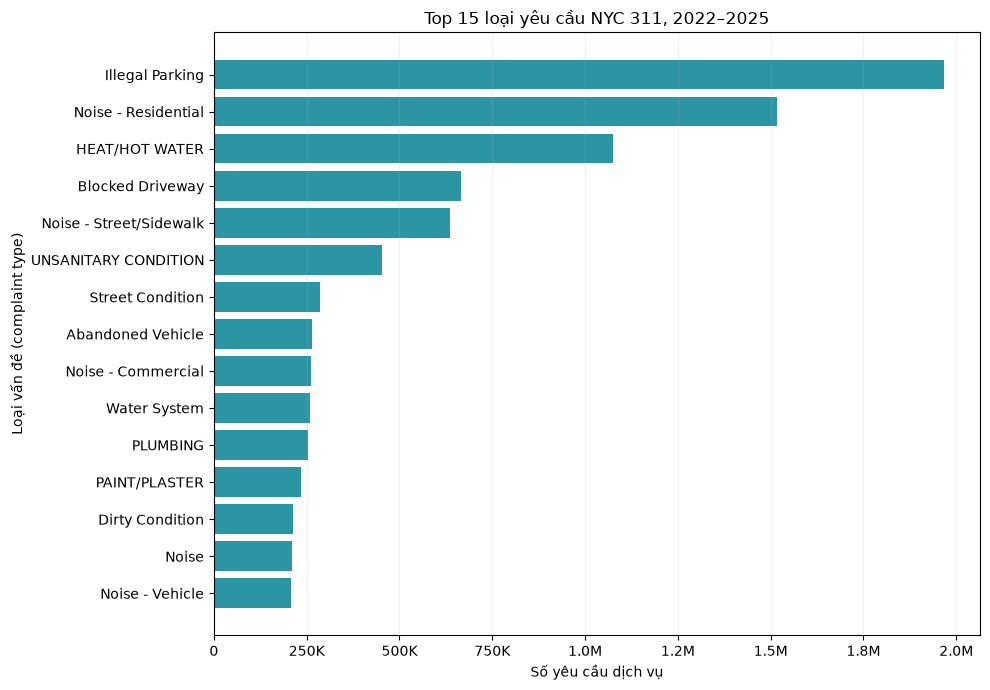

In [8]:
plot_data = (
    top15_complaints
    .sort_values(
        "requests",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(10, 7)
)

ax.barh(
    plot_data["complaint_type"],
    plot_data["requests"],
    color="#2C95A3"
)

ax.xaxis.set_major_formatter(
    MILLION_FORMATTER
)

ax.set_xlabel(
    "Số yêu cầu dịch vụ"
)
ax.set_ylabel(
    "Loại vấn đề (complaint type)"
)
ax.set_title(
    "Top 15 loại yêu cầu NYC 311, 2022–2025"
)

ax.grid(
    axis="x",
    alpha=0.20
)

plt.tight_layout()
plt.show()

In [9]:
# Đóng góp của Illegal Parking vào mức tăng tổng request 2022 -> 2025
illegal_parking_yearly = (
    complaint_by_year[
        complaint_by_year["complaint_type"]
        == "Illegal Parking"
    ]
    .set_index("year")["requests"]
)

total_by_year = (
    yearly_requests
    .set_index("year")["requests"]
)

ip_2022 = int(
    illegal_parking_yearly.loc[2022]
)
ip_2025 = int(
    illegal_parking_yearly.loc[2025]
)

ip_growth_pct = (
    (ip_2025 / ip_2022 - 1)
    * 100
)

ip_delta = (
    ip_2025 - ip_2022
)

total_delta = int(
    total_by_year.loc[2025]
    - total_by_year.loc[2022]
)

ip_contribution_pct = (
    ip_delta
    / total_delta
    * 100
)

print(
    f"Illegal Parking: {ip_2022:,} -> {ip_2025:,} "
    f"({ip_growth_pct:.1f}%)"
)

print(
    f"Increase in Illegal Parking: {ip_delta:,}"
)

print(
    f"Increase in all requests: {total_delta:,}"
)

print(
    "Share of total 2022->2025 increase explained "
    f"arithmetically by Illegal Parking: "
    f"{ip_contribution_pct:.1f}%"
)

Illegal Parking: 405,943 -> 577,257 (42.2%)
Increase in Illegal Parking: 171,314
Increase in all requests: 485,081
Share of total 2022->2025 increase explained arithmetically by Illegal Parking: 35.3%


## Bổ sung cho Q2 — Loại phản ánh nào thực sự kéo mức tăng 2022→2025?

Chỉ nhìn `Illegal Parking` chưa đủ để nói mức tăng toàn hệ thống đến từ thay đổi cơ cấu loại phản ánh. Phần dưới so sánh đồng thời các nhóm tăng mạnh và giảm mạnh, đồng thời theo dõi thay đổi tỷ trọng trong tổng request của từng năm.

In [10]:
# So sánh complaint 2022 -> 2025
complaint_2022 = (
    complaint_by_year[complaint_by_year["year"] == 2022]
    [["complaint_type", "requests"]]
    .rename(columns={"requests": "requests_2022"})
)

complaint_2025 = (
    complaint_by_year[complaint_by_year["year"] == 2025]
    [["complaint_type", "requests"]]
    .rename(columns={"requests": "requests_2025"})
)

complaint_change = (
    complaint_2022
    .merge(complaint_2025, on="complaint_type", how="outer")
    .fillna({"requests_2022": 0, "requests_2025": 0})
)

complaint_change["requests_2022"] = complaint_change["requests_2022"].astype("int64")
complaint_change["requests_2025"] = complaint_change["requests_2025"].astype("int64")
complaint_change["delta_requests"] = (
    complaint_change["requests_2025"] - complaint_change["requests_2022"]
)

total_2022 = int(yearly_requests.loc[yearly_requests["year"] == 2022, "requests"].iloc[0])
total_2025 = int(yearly_requests.loc[yearly_requests["year"] == 2025, "requests"].iloc[0])
total_delta_2022_2025 = total_2025 - total_2022

complaint_change["share_2022_pct"] = complaint_change["requests_2022"] / total_2022 * 100
complaint_change["share_2025_pct"] = complaint_change["requests_2025"] / total_2025 * 100
complaint_change["share_change_pp"] = (
    complaint_change["share_2025_pct"] - complaint_change["share_2022_pct"]
)
complaint_change["contribution_to_net_growth_pct"] = (
    complaint_change["delta_requests"] / total_delta_2022_2025 * 100
)

# Giữ cả nhóm tăng và giảm để tránh chỉ chọn bằng chứng thuận chiều.
top_increase = complaint_change.nlargest(7, "delta_requests")
top_decrease = complaint_change.nsmallest(5, "delta_requests")
complaint_delta_plot = (
    pd.concat([top_increase, top_decrease], ignore_index=True)
    .drop_duplicates(subset=["complaint_type"])
    .sort_values("delta_requests")
    .reset_index(drop=True)
)

COMPLAINT_DELTA_FILE = TABLE_DIR / "complaint_delta_2022_2025.parquet"
complaint_change.to_parquet(COMPLAINT_DELTA_FILE, index=False)

print("Tổng mức tăng 2022 -> 2025:", f"{total_delta_2022_2025:,}")
display(
    complaint_delta_plot[
        [
            "complaint_type",
            "requests_2022",
            "requests_2025",
            "delta_requests",
            "share_2022_pct",
            "share_2025_pct",
            "share_change_pp",
            "contribution_to_net_growth_pct",
        ]
    ].round(2)
)

Tổng mức tăng 2022 -> 2025: 485,081


,complaint_type,requests_2022,requests_2025,delta_requests,share_2022_pct,share_2025_pct,share_change_pp,contribution_to_net_growth_pct
0,Request Large Bulky Item Collection,47008,0,-47008,1.48,0.00,-1.48,-9.69
1,Street Light Condition,57179,33835,-23344,1.80,0.93,-0.88,-4.81
2,Noise - Vehicle,64700,43223,-21477,2.04,1.18,-0.86,-4.43
3,New Tree Request,19517,785,-18732,0.62,0.02,-0.59,-3.86
4,Missed Collection,55441,42977,-12464,1.75,1.18,-0.57,-2.57
5,Dirty Condition,42446,61047,18601,1.34,1.67,0.33,3.83
6,Noise - Street/Sidewalk,153058,173049,19991,4.83,4.73,-0.09,4.12
7,Drug Activity,6955,27964,21009,0.22,0.77,0.55,4.33
8,Vendor Enforcement,0,29117,29117,0.00,0.80,0.80,6.00
9,HEAT/HOT WATER,264390,315946,51556,8.34,8.64,0.30,10.63


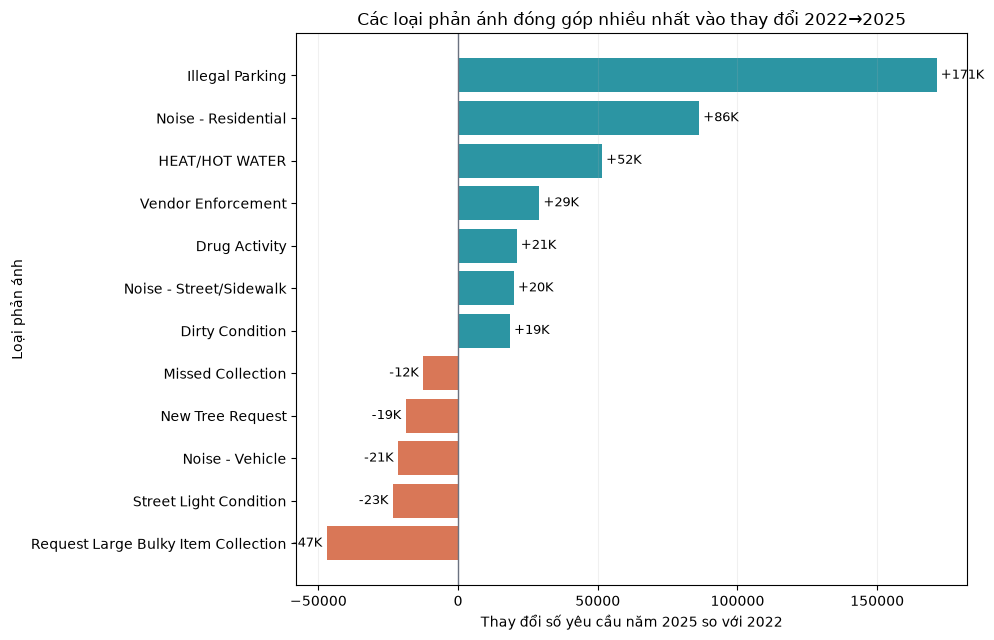

Illegal Parking share: 12.81% (2022) -> 15.79% (2025)
Illegal Parking contribution to net increase: 35.32%
Saved: d:\nyc311_analysis\outputs\charts\complaint_delta_2022_2025.png


In [11]:
fig, ax = plt.subplots(figsize=(10, 6.5))

colors = np.where(
    complaint_delta_plot["delta_requests"] >= 0,
    "#2C95A3",
    "#D97757",
)

ax.barh(
    complaint_delta_plot["complaint_type"],
    complaint_delta_plot["delta_requests"],
    color=colors,
)
ax.axvline(0, linewidth=1, color="#6B7280")

for y, value in enumerate(complaint_delta_plot["delta_requests"]):
    label = f"{value/1000:+.0f}K"
    ax.text(
        value,
        y,
        " " + label if value >= 0 else label + " ",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9,
    )

ax.set_xlabel("Thay đổi số yêu cầu năm 2025 so với 2022")
ax.set_ylabel("Loại phản ánh")
ax.set_title("Các loại phản ánh đóng góp nhiều nhất vào thay đổi 2022→2025")
ax.grid(axis="x", alpha=0.18)

plt.tight_layout()

COMPLAINT_DELTA_CHART = CHART_DIR / "complaint_delta_2022_2025.png"
fig.savefig(COMPLAINT_DELTA_CHART, dpi=180, bbox_inches="tight")
plt.show()

illegal = complaint_change.loc[
    complaint_change["complaint_type"] == "Illegal Parking"
].iloc[0]

print(
    "Illegal Parking share:",
    f"{illegal['share_2022_pct']:.2f}% (2022) -> "
    f"{illegal['share_2025_pct']:.2f}% (2025)"
)
print(
    "Illegal Parking contribution to net increase:",
    f"{illegal['contribution_to_net_growth_pct']:.2f}%"
)
print("Saved:", COMPLAINT_DELTA_CHART)

**Nhận xét.** `Illegal Parking` là nhóm có quy mô lớn nhất trong giai đoạn. Số request của nhóm này tăng từ khoảng **405,9 nghìn năm 2022 lên 577,3 nghìn năm 2025** (khoảng **42,2%**); phần tăng 171,3 nghìn request tương đương khoảng **35,3% mức tăng tổng request** của thành phố từ 2022 đến 2025. Đây là phép phân rã số học của mức tăng, **không phải bằng chứng rằng Illegal Parking gây ra toàn bộ xu hướng tăng**.

# 2. WHEN — Yêu cầu được tạo khi nào?

Đầu tiên xem xu hướng theo tháng. Vì số ngày trong tháng khác nhau, **average daily requests** (số request trung bình/ngày) được dùng làm chỉ báo chính khi so sánh giữa các tháng.

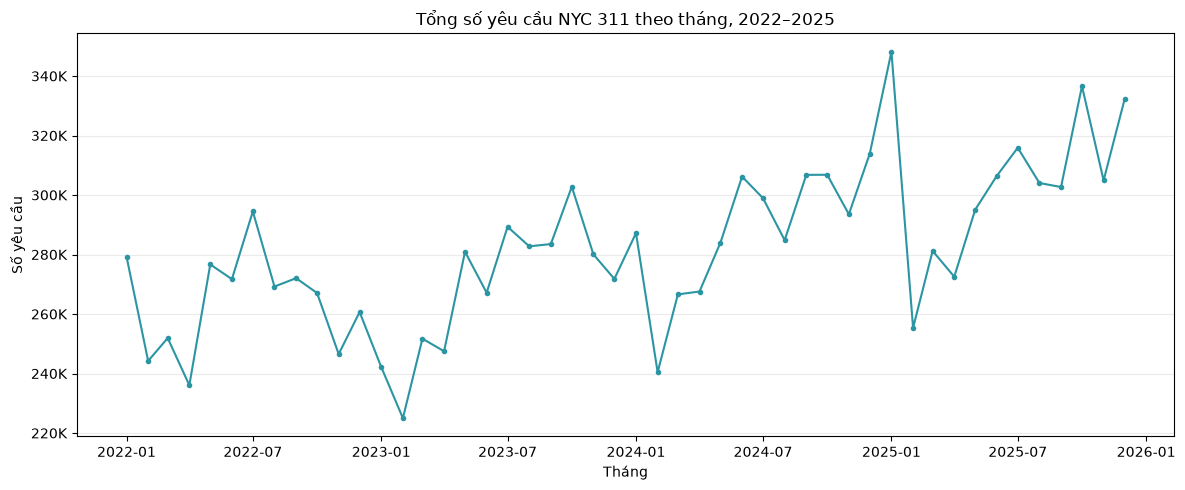

In [12]:
fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    monthly_requests["year_month"],
    monthly_requests["requests"],
    marker="o",
    markersize=3,
    color="#2C95A3"
)

ax.yaxis.set_major_formatter(
    MILLION_FORMATTER
)

ax.set_xlabel("Tháng")
ax.set_ylabel("Số yêu cầu")
ax.set_title(
    "Tổng số yêu cầu NYC 311 theo tháng, 2022–2025"
)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()

**Nhận xét.** Tổng request theo tháng cho thấy biến động ngắn hạn khá rõ, nhưng số ngày của từng tháng không giống nhau. Vì vậy biểu đồ này dùng để quan sát quy mô tuyệt đối; khi so sánh mùa vụ, phần dưới dùng số request trung bình/ngày để tránh việc tháng 31 ngày tự nhiên có lợi thế so với tháng 28–30 ngày.

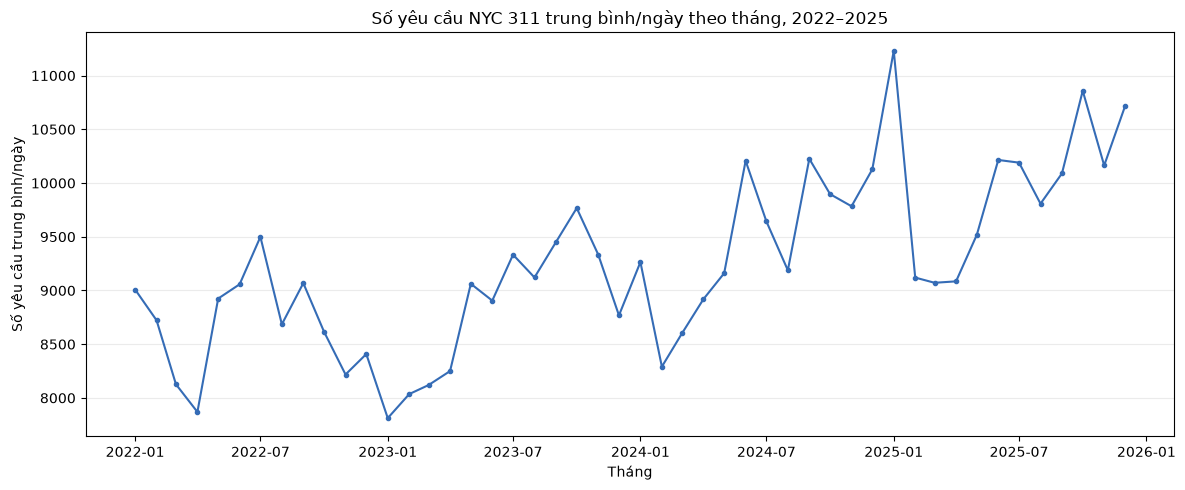

In [13]:
fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    monthly_requests["year_month"],
    monthly_requests["avg_daily_requests"],
    marker="o",
    markersize=3,
    color="#356CB6"
)

ax.set_xlabel("Tháng")
ax.set_ylabel("Số yêu cầu trung bình/ngày")
ax.set_title(
    "Số yêu cầu NYC 311 trung bình/ngày theo tháng, 2022–2025"
)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [14]:
# kiểm tra peak and trough
print("Top 10 months by daily request rate:")

display(
    monthly_requests
    .nlargest(
        10,
        "avg_daily_requests"
    )[
        [
            "year_month",
            "requests",
            "avg_daily_requests"
        ]
    ]
)

print("\nBottom 10 months by daily request rate:")

display(
    monthly_requests
    .nsmallest(
        10,
        "avg_daily_requests"
    )[
        [
            "year_month",
            "requests",
            "avg_daily_requests"
        ]
    ]
)

Top 10 months by daily request rate:


,year_month,requests,avg_daily_requests
36,2025-01-01,348180,11231.612903
45,2025-10-01,336612,10858.451613
47,2025-12-01,332103,10713.000000
32,2024-09-01,306770,10225.666667
41,2025-06-01,306442,10214.733333
29,2024-06-01,306200,10206.666667
42,2025-07-01,315883,10189.774194
46,2025-11-01,304905,10163.500000
35,2024-12-01,313949,10127.387097
44,2025-09-01,302684,10089.466667



Bottom 10 months by daily request rate:


,year_month,requests,avg_daily_requests
12,2023-01-01,242173,7812.032258
3,2022-04-01,236083,7869.433333
13,2023-02-01,225002,8035.785714
14,2023-03-01,251716,8119.870968
2,2022-03-01,251933,8126.870968
10,2022-11-01,246539,8217.966667
15,2023-04-01,247496,8249.866667
25,2024-02-01,240436,8290.896552
11,2022-12-01,260662,8408.451613
26,2024-03-01,266604,8600.129032


In [15]:
# Drill-down tháng 01/2025 và 02/2025 theo complaint_type.
# Ngoài chênh lệch count, tính cả daily rate vì hai tháng có số ngày khác nhau.

jan_file = (
    PROCESSED_DIR
    / "nyc311_2025_01_processed.parquet"
)

feb_file = (
    PROCESSED_DIR
    / "nyc311_2025_02_processed.parquet"
)

jan = pd.read_parquet(
    jan_file,
    columns=["complaint_type"]
).dropna(
    subset=["complaint_type"]
)

feb = pd.read_parquet(
    feb_file,
    columns=["complaint_type"]
).dropna(
    subset=["complaint_type"]
)

jan_counts = (
    jan["complaint_type"]
    .value_counts()
    .rename("jan_requests")
)

feb_counts = (
    feb["complaint_type"]
    .value_counts()
    .rename("feb_requests")
)

jan_feb_detail = (
    pd.concat(
        [
            jan_counts,
            feb_counts
        ],
        axis=1
    )
    .fillna(0)
)

jan_feb_detail["change_requests"] = (
    jan_feb_detail["feb_requests"]
    - jan_feb_detail["jan_requests"]
)

jan_feb_detail["jan_daily"] = (
    jan_feb_detail["jan_requests"]
    / 31
)

jan_feb_detail["feb_daily"] = (
    jan_feb_detail["feb_requests"]
    / 28
)

jan_feb_detail["change_daily"] = (
    jan_feb_detail["feb_daily"]
    - jan_feb_detail["jan_daily"]
)

jan_feb_detail = (
    jan_feb_detail
    .reset_index()
    .rename(
        columns={
            "index": "complaint_type"
        }
    )
)

print(
    "January 2025 requests:",
    f"{len(jan):,}"
)
print(
    "February 2025 requests:",
    f"{len(feb):,}"
)
print(
    "Raw count change:",
    f"{len(feb) - len(jan):,}"
)

print(
    "\nTop complaint types contributing to the raw decrease:"
)

display(
    jan_feb_detail
    .nsmallest(
        10,
        "change_requests"
    )
    [
        [
            "complaint_type",
            "jan_requests",
            "feb_requests",
            "change_requests",
            "jan_daily",
            "feb_daily",
            "change_daily"
        ]
    ]
    .round(1)
)

January 2025 requests: 348,179
February 2025 requests: 255,364
Raw count change: -92,815

Top complaint types contributing to the raw decrease:


,complaint_type,jan_requests,feb_requests,change_requests,jan_daily,feb_daily,change_daily
0,Noise - Residential,70837,26945,-43892,2285.1,962.3,-1322.7
1,HEAT/HOT WATER,67229,40699,-26530,2168.7,1453.5,-715.1
4,UNSANITARY CONDITION,10000,7581,-2419,322.6,270.8,-51.8
10,Snow or Ice,5161,2817,-2344,166.5,100.6,-65.9
3,Blocked Driveway,14661,12516,-2145,472.9,447.0,-25.9
5,PLUMBING,7409,5762,-1647,239.0,205.8,-33.2
6,Water System,6669,5245,-1424,215.1,187.3,-27.8
11,DOOR/WINDOW,4925,3569,-1356,158.9,127.5,-31.4
8,PAINT/PLASTER,5588,4451,-1137,180.3,159.0,-21.3
20,Missed Collection,2994,2025,-969,96.6,72.3,-24.3


**Nhận xét về Jan–Feb/2025.** Tháng 1/2025 có khoảng **348 nghìn** request và tháng 2 khoảng **255 nghìn**, nên count tuyệt đối giảm mạnh. Tuy nhiên tháng 2 chỉ có 28 ngày so với 31 ngày của tháng 1; vì vậy bảng drill-down đồng thời so sánh **daily rate** theo từng `complaint_type`. Chỉ sau bước này mới nên thảo luận nhóm yêu cầu nào thực sự giảm về cường độ; notebook không gán nguyên nhân nhân quả nếu chưa có bằng chứng bổ sung.

In [16]:
if (
    SEASONALITY_FILE.exists()
    and not FORCE_REBUILD
):

    print(
        "Loading cached "
        "seasonality table..."
    )

    monthly_seasonality = (
        pd.read_parquet(
            SEASONALITY_FILE
        )
    )

else:

    print(
        "Building "
        "seasonality table..."
    )

    yearly_daily_baseline = (
        monthly_requests
        .groupby("year")
        .agg(
            total_requests=(
                "requests",
                "sum"
            ),
            total_days=(
                "days_in_month",
                "sum"
            )
        )
        .reset_index()
    )

    yearly_daily_baseline[
        "yearly_avg_daily"
    ] = (
        yearly_daily_baseline[
            "total_requests"
        ]
        /
        yearly_daily_baseline[
            "total_days"
        ]
    )

    monthly_seasonality = (
        monthly_requests
        .merge(
            yearly_daily_baseline[
                [
                    "year",
                    "yearly_avg_daily"
                ]
            ],
            on="year",
            how="left"
        )
    )

    monthly_seasonality[
        "seasonality_index"
    ] = (
        monthly_seasonality[
            "avg_daily_requests"
        ]
        /
        monthly_seasonality[
            "yearly_avg_daily"
        ]
        * 100
    )

    monthly_seasonality.to_parquet(
        SEASONALITY_FILE,
        index=False
    )

    print(
        "Seasonality cache saved."
    )

Building seasonality table...
Seasonality cache saved.


In [17]:
# ==========================
# WHEN
# Yêu cầu xuất hiện khi nào?
# ==========================

seasonality_pivot = (
    monthly_seasonality
    .pivot(
        index="month",
        columns="year",
        values="seasonality_index"
    )
)

seasonality_summary = (
    monthly_seasonality
    .groupby("month")
    .agg(
        median_index=(
            "seasonality_index",
            "median"
        ),
        min_index=(
            "seasonality_index",
            "min"
        ),
        max_index=(
            "seasonality_index",
            "max"
        )
    )
    .reset_index()
)

display(
    seasonality_pivot.round(1)
)

display(
    seasonality_summary.round(1)
)

year,2022,2023,2024,2025
month,,,,
1,103.7,88.4,98.1,112.2
2,100.4,91.0,87.8,91.1
3,93.6,91.9,91.1,90.6
4,90.6,93.4,94.4,90.7
5,102.8,102.6,97.0,95.0
6,104.3,100.8,108.1,102.0
7,109.4,105.6,102.1,101.8
8,100.0,103.2,97.3,97.9
9,104.4,107.0,108.3,100.8


,month,median_index,min_index,max_index
0,1,100.9,88.4,112.2
1,2,91.0,87.8,100.4
2,3,91.5,90.6,93.6
3,4,92.1,90.6,94.4
4,5,99.8,95.0,102.8
5,6,103.1,100.8,108.1
6,7,103.9,101.8,109.4
7,8,99.0,97.3,103.2
8,9,105.7,100.8,108.3
9,10,106.6,99.2,110.5


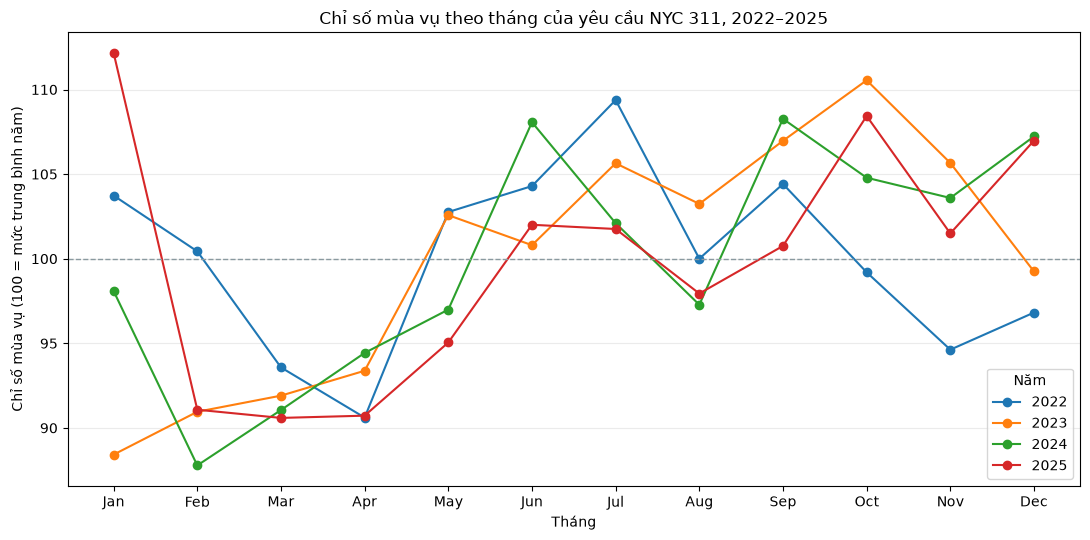

In [18]:
fig, ax = plt.subplots(
    figsize=(11, 5.5)
)

for year in seasonality_pivot.columns:
    ax.plot(
        seasonality_pivot.index,
        seasonality_pivot[year],
        marker="o",
        label=str(year)
    )

ax.axhline(
    100,
    linestyle="--",
    linewidth=1,
    color="#8A9AA0"
)

ax.set_xticks(
    range(1, 13),
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ]
)

ax.set_xlabel("Tháng")
ax.set_ylabel("Chỉ số mùa vụ (100 = mức trung bình năm)")
ax.set_title(
    "Chỉ số mùa vụ theo tháng của yêu cầu NYC 311, 2022–2025"
)

ax.legend(
    title="Năm"
)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()

**Nhận xét.** Sau khi chuẩn hóa theo số ngày và mức nền của từng năm, **March–April thấp hơn baseline 100 trong cả bốn năm**, còn **June–July và September thường cao hơn mức nền**. January biến động khá mạnh giữa các năm, nên không nên mô tả mùa vụ NYC 311 bằng một quy luật cố định cho mọi tháng.

In [19]:
WEEKDAY_HOUR_FILE = (
    TABLE_DIR
    / "weekday_hour_avg.parquet"
)

DAILY_HOUR_FILE = (
    TABLE_DIR
    / "daily_hour_counts.parquet"
)

print(
    "Weekday-hour cache:",
    WEEKDAY_HOUR_FILE
)
print(
    "Daily-hour cache:",
    DAILY_HOUR_FILE
)

Weekday-hour cache: d:\nyc311_analysis\outputs\tables\weekday_hour_avg.parquet
Daily-hour cache: d:\nyc311_analysis\outputs\tables\daily_hour_counts.parquet


In [20]:
weekday_cache_ready = (
    WEEKDAY_HOUR_FILE.exists()
    and DAILY_HOUR_FILE.exists()
    and not FORCE_REBUILD
)

if weekday_cache_ready:
    print(
        "Loading cached weekday-hour tables..."
    )

    weekday_hour_avg = pd.read_parquet(
        WEEKDAY_HOUR_FILE
    )

    daily_hour_all = pd.read_parquet(
        DAILY_HOUR_FILE
    )

else:
    print(
        "Building weekday-hour tables..."
    )

    daily_hour_parts = []

    for i, file in enumerate(
        processed_files,
        start=1
    ):
        part = pd.read_parquet(
            file,
            columns=[
                "created_date"
            ]
        )

        part["date"] = (
            part["created_date"]
            .dt.normalize()
        )

        part["hour"] = (
            part["created_date"]
            .dt.hour
        )

        daily_hour = (
            part
            .groupby(
                [
                    "date",
                    "hour"
                ]
            )
            .size()
            .reset_index(
                name="requests"
            )
        )

        daily_hour_parts.append(
            daily_hour
        )

        print(
            f"[{i:02d}/48] "
            f"{file.name}"
        )

    daily_hour_all = pd.concat(
        daily_hour_parts,
        ignore_index=True
    )

    daily_hour_all[
        "weekday_num"
    ] = (
        daily_hour_all["date"]
        .dt.dayofweek
    )

    weekday_hour_avg = (
        daily_hour_all
        .groupby(
            [
                "weekday_num",
                "hour"
            ],
            as_index=False
        )
        .agg(
            avg_requests=(
                "requests",
                "mean"
            )
        )
    )

    daily_hour_all.to_parquet(
        DAILY_HOUR_FILE,
        index=False
    )

    weekday_hour_avg.to_parquet(
        WEEKDAY_HOUR_FILE,
        index=False
    )

    print(
        "\nWeekday-hour caches saved."
    )

Building weekday-hour tables...
[01/48] nyc311_2022_01_processed.parquet
[02/48] nyc311_2022_02_processed.parquet
[03/48] nyc311_2022_03_processed.parquet
[04/48] nyc311_2022_04_processed.parquet
[05/48] nyc311_2022_05_processed.parquet
[06/48] nyc311_2022_06_processed.parquet
[07/48] nyc311_2022_07_processed.parquet
[08/48] nyc311_2022_08_processed.parquet
[09/48] nyc311_2022_09_processed.parquet
[10/48] nyc311_2022_10_processed.parquet
[11/48] nyc311_2022_11_processed.parquet
[12/48] nyc311_2022_12_processed.parquet
[13/48] nyc311_2023_01_processed.parquet
[14/48] nyc311_2023_02_processed.parquet
[15/48] nyc311_2023_03_processed.parquet
[16/48] nyc311_2023_04_processed.parquet
[17/48] nyc311_2023_05_processed.parquet
[18/48] nyc311_2023_06_processed.parquet
[19/48] nyc311_2023_07_processed.parquet
[20/48] nyc311_2023_08_processed.parquet
[21/48] nyc311_2023_09_processed.parquet
[22/48] nyc311_2023_10_processed.parquet
[23/48] nyc311_2023_11_processed.parquet
[24/48] nyc311_2023_12_pr

In [21]:
print(
    "Rows:",
    len(weekday_hour_avg)
)

print(
    "Weekdays:",
    sorted(
        weekday_hour_avg[
            "weekday_num"
        ].unique()
    )
)

print(
    "Hours:",
    sorted(
        weekday_hour_avg[
            "hour"
        ].unique()
    )
)

print(
    "Missing values:",
    weekday_hour_avg
    .isna()
    .sum()
    .sum()
)

Rows: 168
Weekdays: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)]
Hours: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23)]
Missing values: 0


In [22]:
# ==========================================
# KIỂM TRA ĐỘ PHỦ NGÀY × GIỜ
# ==========================================

total_days = (
    daily_hour_all["date"]
    .nunique()
)

actual_day_hour_slots = len(
    daily_hour_all
)

expected_day_hour_slots = (
    total_days * 24
)

print(
    "Total calendar days:",
    total_days
)

print(
    "Expected day-hour slots:",
    expected_day_hour_slots
)

print(
    "Actual day-hour slots:",
    actual_day_hour_slots
)

print(
    "Missing day-hour slots:",
    expected_day_hour_slots
    - actual_day_hour_slots
)

Total calendar days: 1461
Expected day-hour slots: 35064
Actual day-hour slots: 35061
Missing day-hour slots: 3


In [23]:
weekday_counts = (
    daily_hour_all[
        ["date", "weekday_num"]
    ]
    .drop_duplicates()
    ["weekday_num"]
    .value_counts()
    .sort_index()
)

display(
    weekday_counts
)

weekday_num
0    209
1    209
2    209
3    208
4    208
5    209
6    209
Name: count, dtype: int64

In [24]:
WEEKDAY_NAMES = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

weekday_hour_avg[
    "weekday"
] = (
    weekday_hour_avg[
        "weekday_num"
    ]
    .map(WEEKDAY_NAMES)
)
WEEKDAY_ORDER = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_hour_matrix = (
    weekday_hour_avg
    .pivot(
        index="weekday",
        columns="hour",
        values="avg_requests"
    )
    .reindex(
        WEEKDAY_ORDER
    )
)

display(
    weekday_hour_matrix.round(1)
)

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,
Monday,330.5,204.9,139.0,107.0,104.8,129.5,214.5,366.9,507.6,628.5,...,573.4,558.2,535.6,475.3,460.3,435.5,423.1,436.1,424.7,342.1
Tuesday,255.0,162.7,116.0,94.4,96.1,128.6,227.2,387.4,559.7,652.2,...,561.9,540.7,522.2,478.1,460.8,435.7,431.0,440.0,426.1,345.7
Wednesday,264.5,168.9,121.2,92.9,94.0,126.8,223.7,381.2,543.9,615.2,...,548.3,521.9,501.5,470.6,448.1,423.4,411.3,420.8,417.7,336.9
Thursday,255.1,163.4,113.8,90.3,93.8,122.2,215.0,368.4,532.5,624.9,...,528.6,514.3,493.8,451.1,428.4,406.9,400.9,427.9,431.8,364.7
Friday,282.1,180.7,124.2,98.0,94.1,119.9,204.8,346.6,528.1,602.0,...,525.9,490.6,471.6,442.8,411.4,392.1,391.2,428.0,487.5,458.5
Saturday,415.7,284.6,193.4,142.4,119.6,108.7,151.1,226.9,345.8,405.9,...,395.5,385.1,384.4,374.5,375.2,388.9,416.9,487.2,598.1,588.1
Sunday,539.3,397.5,264.4,187.7,148.8,127.5,150.1,215.5,306.3,369.5,...,405.1,401.2,400.7,405.7,412.1,423.2,435.6,473.3,494.1,408.0


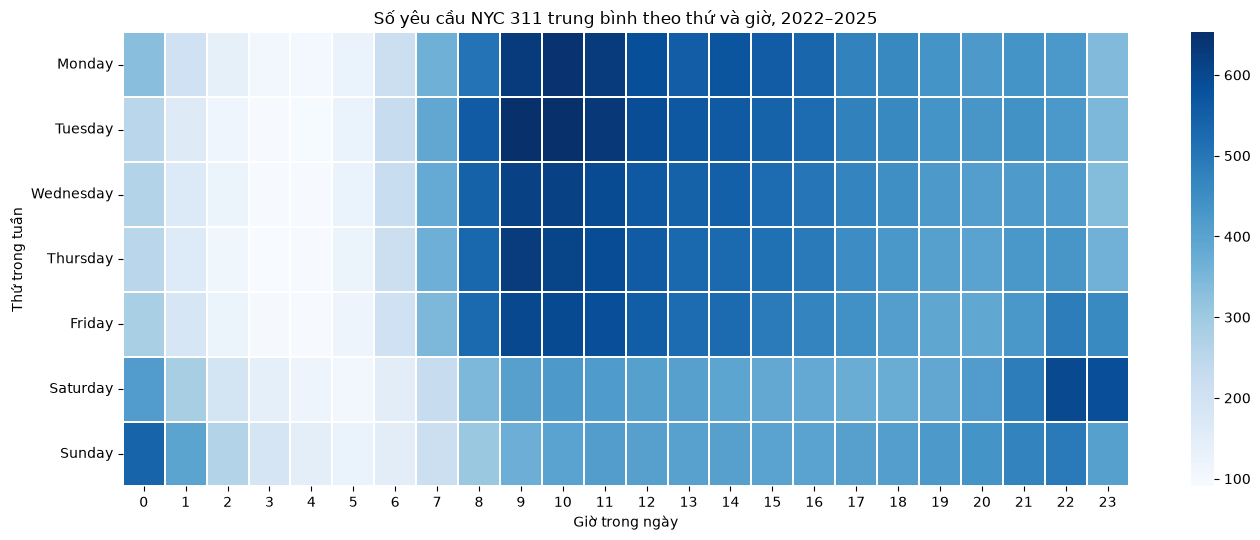

In [25]:
fig, ax = plt.subplots(
    figsize=(14, 5.5)
)

sns.heatmap(
    weekday_hour_matrix,
    linewidths=0.25,
    cmap="Blues",
    ax=ax
)

ax.set_title(
    "Số yêu cầu NYC 311 trung bình theo thứ và giờ, 2022–2025"
)
ax.set_xlabel(
    "Giờ trong ngày"
)
ax.set_ylabel(
    "Thứ trong tuần"
)

plt.tight_layout()
plt.show()

In [26]:
top_time_slots = (
    weekday_hour_avg
    .sort_values(
        "avg_requests",
        ascending=False
    )
    .head(15)
    .copy()
)

top_time_slots["weekday"] = (
    top_time_slots["weekday_num"]
    .map(WEEKDAY_NAMES)
)

top_time_slots["avg_requests"] = (
    top_time_slots["avg_requests"]
    .round(1)
)

display(
    top_time_slots[
        [
            "weekday",
            "hour",
            "avg_requests"
        ]
    ]
)

,weekday,hour,avg_requests
34,Tuesday,10,652.7
33,Tuesday,9,652.2
10,Monday,10,645.0
35,Tuesday,11,633.6
9,Monday,9,628.5
11,Monday,11,628.0
81,Thursday,9,624.9
57,Wednesday,9,615.2
58,Wednesday,10,613.3
82,Thursday,10,610.3


In [27]:
bottom_time_slots = (
    weekday_hour_avg
    .sort_values(
        "avg_requests",
        ascending=True
    )
    .head(10)
    .copy()
)

bottom_time_slots["weekday"] = (
    bottom_time_slots["weekday_num"]
    .map(WEEKDAY_NAMES)
)

bottom_time_slots["avg_requests"] = (
    bottom_time_slots["avg_requests"]
    .round(1)
)

display(
    bottom_time_slots[
        [
            "weekday",
            "hour",
            "avg_requests"
        ]
    ]
)

,weekday,hour,avg_requests
75,Thursday,3,90.3
51,Wednesday,3,92.9
76,Thursday,4,93.8
52,Wednesday,4,94.0
100,Friday,4,94.1
27,Tuesday,3,94.4
28,Tuesday,4,96.1
99,Friday,3,98.0
4,Monday,4,104.8
3,Monday,3,107.0


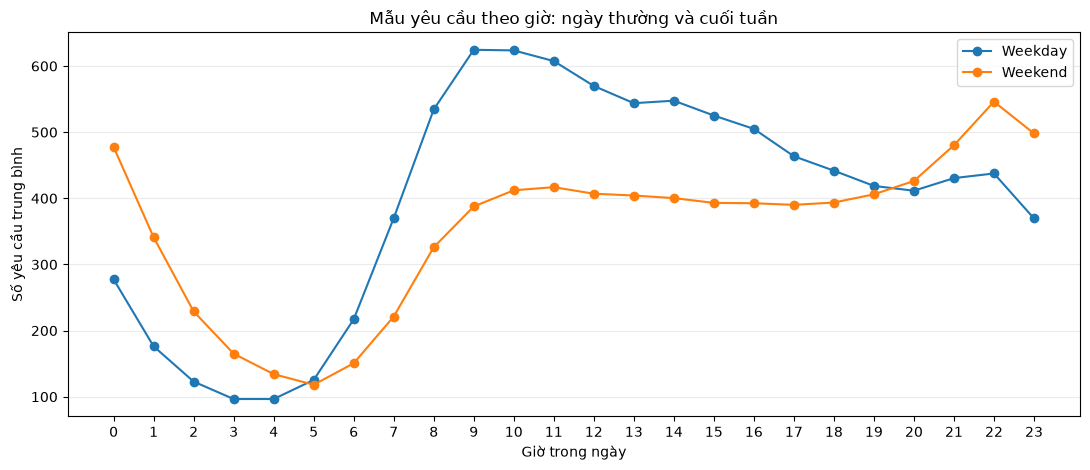

In [28]:
weekday_hour_avg["day_type"] = np.where(
    weekday_hour_avg["weekday_num"] < 5,
    "Weekday",
    "Weekend"
)

day_type_hour = (
    weekday_hour_avg
    .groupby(
        ["day_type", "hour"],
        as_index=False
    )
    .agg(
        avg_requests=(
            "avg_requests",
            "mean"
        )
    )
)

fig, ax = plt.subplots(
    figsize=(11, 4.8)
)

for day_type in [
    "Weekday",
    "Weekend"
]:
    temp = day_type_hour[
        day_type_hour["day_type"]
        == day_type
    ]

    ax.plot(
        temp["hour"],
        temp["avg_requests"],
        marker="o",
        label=day_type
    )

ax.set_xticks(
    range(24)
)
ax.set_xlabel(
    "Giờ trong ngày"
)
ax.set_ylabel(
    "Số yêu cầu trung bình"
)
ax.set_title(
    "Mẫu yêu cầu theo giờ: ngày thường và cuối tuần"
)

ax.legend()
ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()

**Nhận xét.** Khối lượng yêu cầu thấp nhất chủ yếu rơi vào khoảng **03:00–05:00**. Ngày thường tăng mạnh vào buổi sáng và đạt đỉnh khoảng **09:00–11:00**, trong khi cuối tuần có tỷ trọng hoạt động cao hơn vào các giờ muộn, đặc biệt khoảng **21:00–23:00**. Đây là mô tả thời điểm request được tạo; chưa đủ để suy luận nguyên nhân hành vi cụ thể.

# 3. WHERE — Yêu cầu tập trung ở đâu?

Phần đầu dùng số request tuyệt đối theo borough. Sau đó bổ sung một phép chuẩn hóa theo dân số 2020 để cho thấy thứ hạng có thể thay đổi khi kiểm soát quy mô dân số.

In [29]:
BOROUGH_FILE = (
    TABLE_DIR
    / "borough_requests.parquet"
)

print(
    "Borough cache:",
    BOROUGH_FILE
)

Borough cache: d:\nyc311_analysis\outputs\tables\borough_requests.parquet


In [30]:
if (
    BOROUGH_FILE.exists()
    and not FORCE_REBUILD
):

    print(
        "Loading cached borough table..."
    )

    borough_requests = (
        pd.read_parquet(
            BOROUGH_FILE
        )
    )

else:

    print(
        "Building borough table..."
    )

    borough_parts = []

    missing_borough = 0

    for i, file in enumerate(
        processed_files,
        start=1
    ):

        part = pd.read_parquet(
            file,
            columns=[
                "borough"
            ]
        )

        # Đếm request bị thiếu thông tin borough
        missing_borough += int(
            part["borough"]
            .isna()
            .sum()
        )

        # Chỉ aggregate những record có borough
        temp = (
            part
            .dropna(
                subset=["borough"]
            )
            .groupby(
                "borough"
            )
            .size()
            .reset_index(
                name="requests"
            )
        )

        borough_parts.append(temp)

        print(
            f"[{i:02d}/48] "
            f"{file.name}"
        )

    borough_requests = (
        pd.concat(
            borough_parts,
            ignore_index=True
        )
        .groupby(
            "borough",
            as_index=False
        )["requests"]
        .sum()
        .sort_values(
            "requests",
            ascending=False
        )
        .reset_index(drop=True)
    )

    borough_requests.to_parquet(
        BOROUGH_FILE,
        index=False
    )

    print(
        "\nBorough cache saved."
    )

    print(
        "Missing borough:",
        f"{missing_borough:,}"
    )

Building borough table...
[01/48] nyc311_2022_01_processed.parquet
[02/48] nyc311_2022_02_processed.parquet
[03/48] nyc311_2022_03_processed.parquet
[04/48] nyc311_2022_04_processed.parquet
[05/48] nyc311_2022_05_processed.parquet
[06/48] nyc311_2022_06_processed.parquet
[07/48] nyc311_2022_07_processed.parquet
[08/48] nyc311_2022_08_processed.parquet
[09/48] nyc311_2022_09_processed.parquet
[10/48] nyc311_2022_10_processed.parquet
[11/48] nyc311_2022_11_processed.parquet
[12/48] nyc311_2022_12_processed.parquet
[13/48] nyc311_2023_01_processed.parquet
[14/48] nyc311_2023_02_processed.parquet
[15/48] nyc311_2023_03_processed.parquet
[16/48] nyc311_2023_04_processed.parquet
[17/48] nyc311_2023_05_processed.parquet
[18/48] nyc311_2023_06_processed.parquet
[19/48] nyc311_2023_07_processed.parquet
[20/48] nyc311_2023_08_processed.parquet
[21/48] nyc311_2023_09_processed.parquet
[22/48] nyc311_2023_10_processed.parquet
[23/48] nyc311_2023_11_processed.parquet
[24/48] nyc311_2023_12_processe

In [31]:
borough_requests[
    "share_pct"
] = (
    borough_requests["requests"]
    /
    borough_requests["requests"].sum()
    * 100
).round(2)

display(
    borough_requests
)

print(
    "Requests with known borough:",
    f"{borough_requests['requests'].sum():,}"
)

,borough,requests,share_pct
0,BROOKLYN,4050079,30.02
1,QUEENS,3211389,23.80
2,BRONX,2936122,21.76
3,MANHATTAN,2775156,20.57
4,STATEN ISLAND,518683,3.84


Requests with known borough: 13,491,429


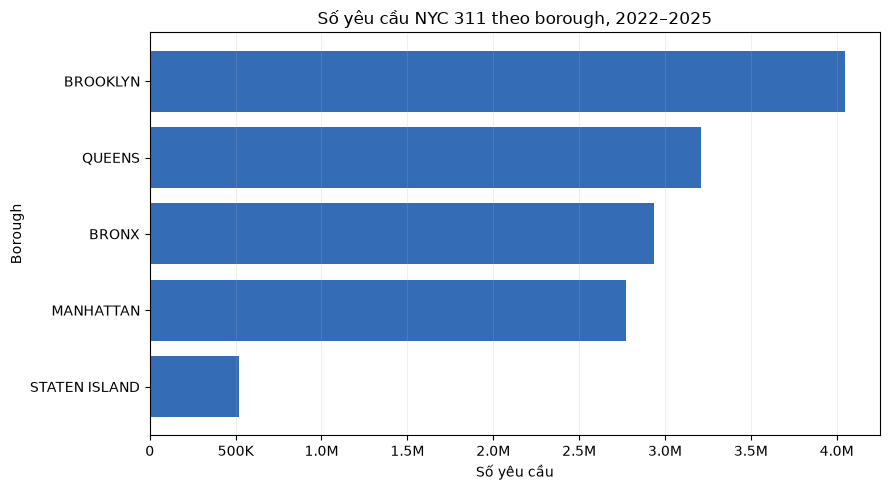

In [32]:
plot_data = (
    borough_requests
    .sort_values(
        "requests",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.barh(
    plot_data["borough"],
    plot_data["requests"],
    color="#356CB6"
)

ax.xaxis.set_major_formatter(
    MILLION_FORMATTER
)

ax.set_xlabel(
    "Số yêu cầu"
)
ax.set_ylabel(
    "Borough"
)
ax.set_title(
    "Số yêu cầu NYC 311 theo borough, 2022–2025"
)

ax.grid(
    axis="x",
    alpha=0.20
)

plt.tight_layout()
plt.show()

**Nhận xét.** Về số lượng tuyệt đối, **Brooklyn** đứng đầu, tiếp theo là Queens, Bronx, Manhattan và Staten Island. Tuy nhiên đây chỉ là recorded request volume; borough có quy mô dân số khác nhau nên không thể diễn giải trực tiếp thành “mức độ vấn đề” hay “nhu cầu trên đầu người”.

### Chuẩn hóa theo dân số 2020

Bảng dân số tham chiếu sử dụng **2020 Census**, Population Division — NYC Department of City Planning. Đây là denominator cố định để so sánh quy mô tương đối giữa borough, **không phải dân số động cho từng năm 2022–2025**.

Nguồn: [NYC Department of City Planning — 2020 Census Results](https://www.nyc.gov/assets/planning/download/pdf/planning-level/nyc-population/census2020/dcp_2020-census-briefing-booklet-1.pdf)

In [33]:
BOROUGH_POPULATION_FILE = (
    EXTERNAL_DIR
    / "nyc_borough_population_2020.csv"
)

borough_population_2020 = pd.DataFrame({
    "borough": [
        "BRONX",
        "BROOKLYN",
        "MANHATTAN",
        "QUEENS",
        "STATEN ISLAND"
    ],
    "population_2020": [
        1_472_654,
        2_736_074,
        1_694_251,
        2_405_464,
        495_747
    ]
})

borough_population_2020.to_csv(
    BOROUGH_POPULATION_FILE,
    index=False
)

borough_normalized = (
    borough_requests
    .merge(
        borough_population_2020,
        on="borough",
        how="inner"
    )
)

borough_normalized[
    "requests_per_resident_4y"
] = (
    borough_normalized["requests"]
    / borough_normalized["population_2020"]
)

display(
    borough_normalized[
        [
            "borough",
            "requests",
            "population_2020",
            "requests_per_resident_4y"
        ]
    ]
    .sort_values(
        "requests_per_resident_4y",
        ascending=False
    )
    .round({
        "requests_per_resident_4y": 2
    })
)

print(
    "Saved reference population table:",
    BOROUGH_POPULATION_FILE
)

,borough,requests,population_2020,requests_per_resident_4y
2,BRONX,2936122,1472654,1.99
3,MANHATTAN,2775156,1694251,1.64
0,BROOKLYN,4050079,2736074,1.48
1,QUEENS,3211389,2405464,1.34
4,STATEN ISLAND,518683,495747,1.05


Saved reference population table: d:\nyc311_analysis\data\external\nyc_borough_population_2020.csv


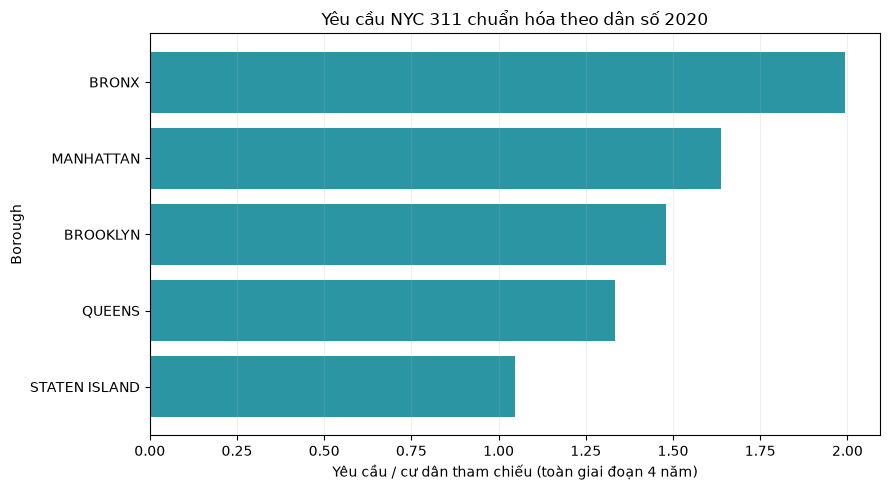

In [34]:
plot_data = (
    borough_normalized
    .sort_values(
        "requests_per_resident_4y",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.barh(
    plot_data["borough"],
    plot_data[
        "requests_per_resident_4y"
    ],
    color="#2C95A3"
)

ax.set_xlabel(
    "Yêu cầu / cư dân tham chiếu (toàn giai đoạn 4 năm)"
)
ax.set_ylabel(
    "Borough"
)
ax.set_title(
    "Yêu cầu NYC 311 chuẩn hóa theo dân số 2020"
)

ax.grid(
    axis="x",
    alpha=0.20
)

plt.tight_layout()
plt.show()

**Nhận xét.** Sau khi chuẩn hóa bằng dân số Census 2020, thứ hạng thay đổi: **Bronx** có khoảng **1,99 request trên mỗi cư dân tham chiếu trong bốn năm**, cao hơn Manhattan (~1,64), Brooklyn (~1,48), Queens (~1,34) và Staten Island (~1,05). Điều này cho thấy kết luận “Brooklyn cao nhất” chỉ đúng với **số lượng tuyệt đối**, không đúng khi điều chỉnh theo quy mô dân số. Chỉ số này không có nghĩa mỗi cư dân thực tế đã gửi đúng số request đó vì dữ liệu 311 không định danh unique resident.

In [35]:
BOROUGH_COMPLAINT_FILE = (
    TABLE_DIR
    / "borough_complaint.parquet"
)

In [36]:
if (
    BOROUGH_COMPLAINT_FILE.exists()
    and not FORCE_REBUILD
):

    print(
        "Loading cached "
        "borough-complaint table..."
    )

    borough_complaint = (
        pd.read_parquet(
            BOROUGH_COMPLAINT_FILE
        )
    )

else:

    print(
        "Building borough-complaint table..."
    )

    borough_complaint_parts = []

    for i, file in enumerate(
        processed_files,
        start=1
    ):

        part = pd.read_parquet(
            file,
            columns=[
                "borough",
                "complaint_type"
            ]
        )

        # Chỉ dùng các dòng biết cả borough
        # và loại vấn đề
        part = part.dropna(
            subset=[
                "borough",
                "complaint_type"
            ]
        )

        temp = (
            part
            .groupby(
                [
                    "borough",
                    "complaint_type"
                ]
            )
            .size()
            .reset_index(
                name="requests"
            )
        )

        borough_complaint_parts.append(
            temp
        )

        print(
            f"[{i:02d}/48] "
            f"{file.name}"
        )

    borough_complaint = (
        pd.concat(
            borough_complaint_parts,
            ignore_index=True
        )
        .groupby(
            [
                "borough",
                "complaint_type"
            ],
            as_index=False
        )["requests"]
        .sum()
    )

    borough_complaint.to_parquet(
        BOROUGH_COMPLAINT_FILE,
        index=False
    )

    print(
        "\nBorough-complaint cache saved."
    )

Building borough-complaint table...
[01/48] nyc311_2022_01_processed.parquet
[02/48] nyc311_2022_02_processed.parquet
[03/48] nyc311_2022_03_processed.parquet
[04/48] nyc311_2022_04_processed.parquet
[05/48] nyc311_2022_05_processed.parquet
[06/48] nyc311_2022_06_processed.parquet
[07/48] nyc311_2022_07_processed.parquet
[08/48] nyc311_2022_08_processed.parquet
[09/48] nyc311_2022_09_processed.parquet
[10/48] nyc311_2022_10_processed.parquet
[11/48] nyc311_2022_11_processed.parquet
[12/48] nyc311_2022_12_processed.parquet
[13/48] nyc311_2023_01_processed.parquet
[14/48] nyc311_2023_02_processed.parquet
[15/48] nyc311_2023_03_processed.parquet
[16/48] nyc311_2023_04_processed.parquet
[17/48] nyc311_2023_05_processed.parquet
[18/48] nyc311_2023_06_processed.parquet
[19/48] nyc311_2023_07_processed.parquet
[20/48] nyc311_2023_08_processed.parquet
[21/48] nyc311_2023_09_processed.parquet
[22/48] nyc311_2023_10_processed.parquet
[23/48] nyc311_2023_11_processed.parquet
[24/48] nyc311_2023_1

In [37]:
top10_complaints = (
    complaint_total
    .head(10)[
        "complaint_type"
    ]
    .tolist()
)

print(
    top10_complaints
)

['Illegal Parking', 'Noise - Residential', 'HEAT/HOT WATER', 'Blocked Driveway', 'Noise - Street/Sidewalk', 'UNSANITARY CONDITION', 'Street Condition', 'Abandoned Vehicle', 'Noise - Commercial', 'Water System']


In [38]:
COMMUNITY_BOARD_PROFILE_FILE = (
    TABLE_DIR
    / "community_board_profile.parquet"
)

if (
    COMMUNITY_BOARD_PROFILE_FILE.exists()
    and not FORCE_REBUILD
):

    print(
        "Loading cached "
        "community board profile..."
    )

    community_board_profile = (
        pd.read_parquet(
            COMMUNITY_BOARD_PROFILE_FILE
        )
    )

else:

    print(
        "Building community board profile..."
    )

    board_parts = []

    for i, file in enumerate(
        processed_files,
        start=1
    ):

        part = pd.read_parquet(
            file,
            columns=[
                "community_board"
            ]
        )

        temp = (
            part
            .groupby(
                "community_board",
                dropna=False
            )
            .size()
            .reset_index(
                name="requests"
            )
        )

        board_parts.append(temp)

        print(
            f"[{i:02d}/48] "
            f"{file.name}"
        )

    community_board_profile = (
        pd.concat(
            board_parts,
            ignore_index=True
        )
        .groupby(
            "community_board",
            dropna=False,
            as_index=False
        )["requests"]
        .sum()
        .sort_values(
            "requests",
            ascending=False
        )
        .reset_index(drop=True)
    )

    community_board_profile.to_parquet(
        COMMUNITY_BOARD_PROFILE_FILE,
        index=False
    )

Building community board profile...
[01/48] nyc311_2022_01_processed.parquet
[02/48] nyc311_2022_02_processed.parquet
[03/48] nyc311_2022_03_processed.parquet
[04/48] nyc311_2022_04_processed.parquet
[05/48] nyc311_2022_05_processed.parquet
[06/48] nyc311_2022_06_processed.parquet
[07/48] nyc311_2022_07_processed.parquet
[08/48] nyc311_2022_08_processed.parquet
[09/48] nyc311_2022_09_processed.parquet
[10/48] nyc311_2022_10_processed.parquet
[11/48] nyc311_2022_11_processed.parquet
[12/48] nyc311_2022_12_processed.parquet
[13/48] nyc311_2023_01_processed.parquet
[14/48] nyc311_2023_02_processed.parquet
[15/48] nyc311_2023_03_processed.parquet
[16/48] nyc311_2023_04_processed.parquet
[17/48] nyc311_2023_05_processed.parquet
[18/48] nyc311_2023_06_processed.parquet
[19/48] nyc311_2023_07_processed.parquet
[20/48] nyc311_2023_08_processed.parquet
[21/48] nyc311_2023_09_processed.parquet
[22/48] nyc311_2023_10_processed.parquet
[23/48] nyc311_2023_11_processed.parquet
[24/48] nyc311_2023_1

In [39]:
print(
    "Unique community_board values:",
    community_board_profile[
        "community_board"
    ].nunique(dropna=False)
)

display(
    community_board_profile.head(30)
)

Unique community_board values: 77


,community_board,requests
0,12 BRONX,554136
1,12 MANHATTAN,413209
2,04 BRONX,336751
3,01 BROOKLYN,335333
4,05 BROOKLYN,334374
5,01 QUEENS,312701
6,07 BRONX,312557
7,12 QUEENS,310403
8,05 QUEENS,310084
9,10 MANHATTAN,308950


In [40]:
board_text = (
    community_board_profile[
        "community_board"
    ]
    .astype("string")
)

suspicious_board = (
    board_text.isna()
    |
    board_text.str.contains(
        "Unspecified",
        case=False,
        na=False
    )
    |
    board_text.str.startswith(
        "0 ",
        na=False
    )
)

display(
    community_board_profile[
        suspicious_board
    ]
)

,community_board,requests
59,Unspecified MANHATTAN,66231
60,Unspecified QUEENS,46284
61,Unspecified BROOKLYN,42287
62,Unspecified BRONX,22160
63,0 Unspecified,15065
70,Unspecified STATEN ISLAND,4525


In [41]:
# ==========================================
# PARSE COMMUNITY BOARD
# Tách số board và borough
# ==========================================

community_board_check = (
    community_board_profile.copy()
)

board_text = (
    community_board_check["community_board"]
    .astype("string")
    .str.strip()
)

parsed = board_text.str.extract(
    r"^(?P<board_num>\d{1,2}) "
    r"(?P<board_borough>"
    r"BRONX|BROOKLYN|MANHATTAN|QUEENS|STATEN ISLAND"
    r")$"
)

community_board_check["board_num"] = (
    pd.to_numeric(
        parsed["board_num"],
        errors="coerce"
    )
)

community_board_check["board_borough"] = (
    parsed["board_borough"]
)

display(
    community_board_check.head(15)
)

,community_board,requests,board_num,board_borough
0,12 BRONX,554136,12,BRONX
1,12 MANHATTAN,413209,12,MANHATTAN
2,04 BRONX,336751,4,BRONX
3,01 BROOKLYN,335333,1,BROOKLYN
4,05 BROOKLYN,334374,5,BROOKLYN
5,01 QUEENS,312701,1,QUEENS
6,07 BRONX,312557,7,BRONX
7,12 QUEENS,310403,12,QUEENS
8,05 QUEENS,310084,5,QUEENS
9,10 MANHATTAN,308950,10,MANHATTAN


In [42]:
# ==========================================
# CLASSIFY COMMUNITY BOARD VALUES
# Phân loại giá trị community_board
# ==========================================

BOARD_LIMITS = {
    "BRONX": 12,
    "BROOKLYN": 18,
    "MANHATTAN": 12,
    "QUEENS": 14,
    "STATEN ISLAND": 3
}

# Joint Interest Area
# = khu vực đặc biệt, không phải Community Board thông thường
JIA_CODES = {
    "BRONX": {26, 27, 28},
    "BROOKLYN": {55, 56},
    "MANHATTAN": {64},
    "QUEENS": {80, 81, 82, 83, 84},
    "STATEN ISLAND": {95}
}


def classify_board(row):

    borough = row["board_borough"]
    num = row["board_num"]

    # Không parse được:
    # ví dụ "Unspecified MANHATTAN"
    if pd.isna(borough) or pd.isna(num):
        return "Unspecified"

    num = int(num)

    # Community Board chính thức
    if 1 <= num <= BOARD_LIMITS[borough]:
        return "Community Board"

    # Joint Interest Area
    if num in JIA_CODES.get(borough, set()):
        return "Joint Interest Area"

    # Nếu còn loại khác
    return "Other"


community_board_check["board_type"] = (
    community_board_check.apply(
        classify_board,
        axis=1
    )
)

display(
    community_board_check[
        [
            "community_board",
            "requests",
            "board_num",
            "board_borough",
            "board_type"
        ]
    ].head(20)
)

,community_board,requests,board_num,board_borough,board_type
0,12 BRONX,554136,12,BRONX,Community Board
1,12 MANHATTAN,413209,12,MANHATTAN,Community Board
2,04 BRONX,336751,4,BRONX,Community Board
3,01 BROOKLYN,335333,1,BROOKLYN,Community Board
4,05 BROOKLYN,334374,5,BROOKLYN,Community Board
5,01 QUEENS,312701,1,QUEENS,Community Board
6,07 BRONX,312557,7,BRONX,Community Board
7,12 QUEENS,310403,12,QUEENS,Community Board
8,05 QUEENS,310084,5,QUEENS,Community Board
9,10 MANHATTAN,308950,10,MANHATTAN,Community Board


In [43]:
board_type_summary = (
    community_board_check
    .groupby("board_type")
    .agg(
        unique_values=(
            "community_board",
            "count"
        ),
        requests=(
            "requests",
            "sum"
        )
    )
    .reset_index()
)

display(board_type_summary)

print("\nOther values:")

display(
    community_board_check[
        community_board_check["board_type"]
        == "Other"
    ][
        [
            "community_board",
            "requests",
            "board_num",
            "board_borough"
        ]
    ]
)

,board_type,unique_values,requests
0,Community Board,59,13252902
1,Joint Interest Area,12,57040
2,Unspecified,6,196552



Other values:


,community_board,requests,board_num,board_borough


In [44]:
print("=== COMMUNITY BOARD VALIDATION ===")

print(
    "Total category values:",
    len(community_board_check)
)

print(
    "Valid Community Boards:",
    (
        community_board_check["board_type"]
        == "Community Board"
    ).sum()
)

print(
    "Joint Interest Areas:",
    (
        community_board_check["board_type"]
        == "Joint Interest Area"
    ).sum()
)

print(
    "Unspecified values:",
    (
        community_board_check["board_type"]
        == "Unspecified"
    ).sum()
)

print(
    "Other values:",
    (
        community_board_check["board_type"]
        == "Other"
    ).sum()
)

print(
    "Total requests:",
    f"{community_board_check['requests'].sum():,}"
)

=== COMMUNITY BOARD VALIDATION ===
Total category values: 77
Valid Community Boards: 59
Joint Interest Areas: 12
Unspecified values: 6
Other values: 0
Total requests: 13,506,494


In [45]:
COMMUNITY_BOARD_FILE = (
    TABLE_DIR
    / "community_board_requests.parquet"
)

community_board_requests = (
    community_board_check[
        community_board_check["board_type"]
        == "Community Board"
    ][
        [
            "community_board",
            "board_num",
            "board_borough",
            "requests"
        ]
    ]
    .copy()
)

community_board_requests = (
    community_board_requests
    .sort_values(
        "requests",
        ascending=False
    )
    .reset_index(drop=True)
)

# Tỷ trọng trong riêng 59 Community Board
community_board_requests[
    "share_pct"
] = (
    community_board_requests["requests"]
    /
    community_board_requests["requests"].sum()
    * 100
)

community_board_requests.to_parquet(
    COMMUNITY_BOARD_FILE,
    index=False
)

print(
    "Rows:",
    len(community_board_requests)
)

print(
    "Requests in 59 Community Boards:",
    f"{community_board_requests['requests'].sum():,}"
)

display(
    community_board_requests.head(10)
)

Rows: 59
Requests in 59 Community Boards: 13,252,902


,community_board,board_num,board_borough,requests,share_pct
0,12 BRONX,12,BRONX,554136,4.181243
1,12 MANHATTAN,12,MANHATTAN,413209,3.117876
2,04 BRONX,4,BRONX,336751,2.540960
3,01 BROOKLYN,1,BROOKLYN,335333,2.530261
4,05 BROOKLYN,5,BROOKLYN,334374,2.523025
5,01 QUEENS,1,QUEENS,312701,2.359491
6,07 BRONX,7,BRONX,312557,2.358404
7,12 QUEENS,12,QUEENS,310403,2.342151
8,05 QUEENS,5,QUEENS,310084,2.339744
9,10 MANHATTAN,10,MANHATTAN,308950,2.331188


In [46]:
print("Top 10 Community Boards:")

display(
    community_board_requests
    .head(10)
)

print("\nBottom 10 Community Boards:")

display(
    community_board_requests
    .tail(10)
    .sort_values(
        "requests",
        ascending=True
    )
)

print("\nRequest distribution:")

display(
    community_board_requests[
        "requests"
    ].describe(
        percentiles=[
            0.25,
            0.5,
            0.75,
            0.9
        ]
    )
)

Top 10 Community Boards:


,community_board,board_num,board_borough,requests,share_pct
0,12 BRONX,12,BRONX,554136,4.181243
1,12 MANHATTAN,12,MANHATTAN,413209,3.117876
2,04 BRONX,4,BRONX,336751,2.540960
3,01 BROOKLYN,1,BROOKLYN,335333,2.530261
4,05 BROOKLYN,5,BROOKLYN,334374,2.523025
5,01 QUEENS,1,QUEENS,312701,2.359491
6,07 BRONX,7,BRONX,312557,2.358404
7,12 QUEENS,12,QUEENS,310403,2.342151
8,05 QUEENS,5,QUEENS,310084,2.339744
9,10 MANHATTAN,10,MANHATTAN,308950,2.331188



Bottom 10 Community Boards:


,community_board,board_num,board_borough,requests,share_pct
58,02 BRONX,2,BRONX,101837,0.768413
57,13 BROOKLYN,13,BROOKLYN,111409,0.840639
56,01 MANHATTAN,1,MANHATTAN,115537,0.871786
55,11 QUEENS,11,QUEENS,125413,0.946306
54,16 BROOKLYN,16,BROOKLYN,125426,0.946404
53,02 STATEN ISLAND,2,STATEN ISLAND,135876,1.025255
52,06 QUEENS,6,QUEENS,136749,1.031842
51,14 QUEENS,14,QUEENS,138042,1.041598
50,06 MANHATTAN,6,MANHATTAN,143831,1.085279
49,10 BRONX,10,BRONX,150302,1.134106



Request distribution:


count        59.000000
mean     224625.457627
std       78774.130415
min      101837.000000
25%      181635.500000
50%      211101.000000
75%      269865.000000
90%      312585.800000
max      554136.000000
Name: requests, dtype: float64

In [47]:
BOROUGH_CODE = {
    "MANHATTAN": 1,
    "BRONX": 2,
    "BROOKLYN": 3,
    "QUEENS": 4,
    "STATEN ISLAND": 5
}

community_board_requests["borough_code"] = (
    community_board_requests["board_borough"]
    .map(BOROUGH_CODE)
)

community_board_requests["boro_cd"] = (
    community_board_requests["borough_code"] * 100
    + community_board_requests["board_num"]
)

display(
    community_board_requests[
        [
            "community_board",
            "board_borough",
            "board_num",
            "boro_cd",
            "requests"
        ]
    ].head(15)
)

,community_board,board_borough,board_num,boro_cd,requests
0,12 BRONX,BRONX,12,212,554136
1,12 MANHATTAN,MANHATTAN,12,112,413209
2,04 BRONX,BRONX,4,204,336751
3,01 BROOKLYN,BROOKLYN,1,301,335333
4,05 BROOKLYN,BROOKLYN,5,305,334374
5,01 QUEENS,QUEENS,1,401,312701
6,07 BRONX,BRONX,7,207,312557
7,12 QUEENS,QUEENS,12,412,310403
8,05 QUEENS,QUEENS,5,405,310084
9,10 MANHATTAN,MANHATTAN,10,110,308950


In [48]:
print(
    "Rows:",
    len(community_board_requests)
)

print(
    "Unique boro_cd:",
    community_board_requests["boro_cd"].nunique()
)

print(
    "Duplicate boro_cd:",
    community_board_requests["boro_cd"]
    .duplicated()
    .sum()
)

print(
    "Missing boro_cd:",
    community_board_requests["boro_cd"]
    .isna()
    .sum()
)

Rows: 59
Unique boro_cd: 59
Duplicate boro_cd: 0
Missing boro_cd: 0


In [49]:
import json

GEOJSON_FILE = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "nyc_community_districts.geojson"
)

print("GeoJSON exists:", GEOJSON_FILE.exists())

with open(
    GEOJSON_FILE,
    "r",
    encoding="utf-8"
) as f:
    community_geojson = json.load(f)

print(
    "GeoJSON type:",
    community_geojson["type"]
)

print(
    "Number of features:",
    len(community_geojson["features"])
)

print(
    "\nFirst feature properties:"
)

print(
    community_geojson[
        "features"
    ][0]["properties"]
)

GeoJSON exists: True
GeoJSON type: FeatureCollection
Number of features: 71

First feature properties:
{'boro_cd': '410', 'shape_leng': '105822.37731', 'shape_area': '172077374.82'}


In [50]:
valid_boro_cd = set(
    community_board_requests[
        "boro_cd"
    ]
    .astype(int)
    .tolist()
)

filtered_features = []

for feature in community_geojson[
    "features"
]:

    raw_code = (
        feature["properties"]
        .get("boro_cd")
    )

    if raw_code is None:
        continue

    code = int(raw_code)

    if code in valid_boro_cd:

        # Chuẩn hóa về string để Plotly join ổn định
        feature["properties"][
            "boro_cd"
        ] = str(code)

        filtered_features.append(
            feature
        )

community_board_geojson = {
    "type": "FeatureCollection",
    "features": filtered_features
}

print(
    "Filtered geographic features:",
    len(filtered_features)
)

Filtered geographic features: 59


In [51]:
data_codes = set(
    community_board_requests[
        "boro_cd"
    ]
    .astype(int)
)

geo_codes = {
    int(
        feature["properties"][
            "boro_cd"
        ]
    )
    for feature
    in community_board_geojson[
        "features"
    ]
}

print(
    "Data codes:",
    len(data_codes)
)

print(
    "GeoJSON codes:",
    len(geo_codes)
)

print(
    "Data missing from GeoJSON:",
    sorted(
        data_codes - geo_codes
    )
)

print(
    "GeoJSON missing from data:",
    sorted(
        geo_codes - data_codes
    )
)

Data codes: 59
GeoJSON codes: 59
Data missing from GeoJSON: []
GeoJSON missing from data: []


In [52]:
map_data = (
    community_board_requests
    .copy()
)

map_data["boro_cd_str"] = (
    map_data["boro_cd"]
    .astype(int)
    .astype(str)
)

fig = px.choropleth(
    map_data,
    geojson=community_board_geojson,
    locations="boro_cd_str",
    featureidkey="properties.boro_cd",
    color="requests",
    hover_name="community_board",
    hover_data={
        "boro_cd_str": False,
        "board_borough": True,
        "requests": ":,",
        "share_pct": ":.2f"
    },
    labels={
        "requests": "Số yêu cầu",
        "board_borough": "Borough",
        "share_pct": "Tỷ trọng (%)"
    },
    title=(
        "Số yêu cầu NYC 311 theo Community Board, 2022–2025"
    ),
    color_continuous_scale="Blues"
)

fig.update_geos(
    fitbounds="locations",
    visible=False,
    projection_type="mercator"
)

fig.update_layout(
    height=650,
    margin={
        "l": 0,
        "r": 70,
        "t": 60,
        "b": 0
    },
    coloraxis_colorbar={
        "title": "Số yêu cầu",
        "thickness": 15,
        "len": 0.65
    }
)

fig.show()

MAP_FILE = (
    CHART_DIR
    / "community_board_requests_map.html"
)

fig.write_html(
    MAP_FILE
)

print(
    "Saved:",
    MAP_FILE
)

Saved: d:\nyc311_analysis\outputs\charts\community_board_requests_map.html


**Nhận xét.** Community Board 12 Bronx có số request tuyệt đối cao nhất trong 59 Community Boards. Bản đồ chỉ biểu diễn **recorded request count**, chưa chuẩn hóa theo dân số hay diện tích từng board; vì vậy màu đậm không được diễn giải trực tiếp thành mức độ nghiêm trọng của vấn đề.

# 4. HOW LONG — Mất bao lâu để yêu cầu được đóng?

Toàn bộ thống kê closure ở phần này được **tính lại trực tiếp từ `created_date` và `closed_date`** trên cùng snapshot `08/10/2026 22:21:35`.

Một bản ghi chỉ được tính thời gian đóng khi đồng thời thỏa **ba điều kiện**:

1. `closed_date` có giá trị.
2. `closed_date >= created_date`.
3. `closed_date <= SNAPSHOT_DATE`.

Các request chưa đóng tại snapshot không có eventual closure time nên không xuất hiện trong phân phối `closure_hours`. Đây là **right-censoring**, cần được nhắc khi diễn giải.


In [53]:
CLOSURE_SUMMARY_FILE = TABLE_DIR / "closure_overall_summary_final.parquet"

def add_final_closure_fields(part):
    part = part.copy()

    valid = (
        part["closed_date"].notna()
        & part["created_date"].notna()
        & (part["closed_date"] >= part["created_date"])
        & (part["closed_date"] <= SNAPSHOT_DATE)
    )

    part["closure_valid_final"] = valid
    part["closure_hours_final"] = np.where(
        valid,
        (part["closed_date"] - part["created_date"]).dt.total_seconds() / 3600,
        np.nan,
    )
    return part


closure_arrays = []
total_requests = 0
valid_closure_requests = 0
stored_flag_mismatch = 0

for i, file in enumerate(processed_files, start=1):
    cols = ["created_date", "closed_date"]
    stored_columns = pd.read_parquet(file).columns

    if "closure_valid" in stored_columns:
        cols.append("closure_valid")

    part = pd.read_parquet(file, columns=cols)
    part = add_final_closure_fields(part)

    total_requests += len(part)
    valid_closure_requests += int(part["closure_valid_final"].sum())

    if "closure_valid" in part.columns:
        stored_flag_mismatch += int(
            (
                part["closure_valid"].fillna(False).astype(bool)
                != part["closure_valid_final"]
            ).sum()
        )

    valid_values = (
        part.loc[part["closure_valid_final"], "closure_hours_final"]
        .dropna()
        .to_numpy(dtype="float64")
    )
    closure_arrays.append(valid_values)

    print(f"[{i:02d}/48] {file.name}")

closure_values = np.concatenate(closure_arrays)
invalid_closure_requests = total_requests - valid_closure_requests

closure_summary_final = pd.DataFrame(
    {
        "snapshot": [SNAPSHOT_DATE] * 10,
        "metric": [
            "Total requests",
            "Valid closure requests",
            "Invalid/unavailable closure",
            "Valid closure (%)",
            "Mean closure hours",
            "Median closure hours",
            "P75 closure hours",
            "P90 closure hours",
            "P95 closure hours",
            "P99 closure hours",
        ],
        "value": [
            total_requests,
            valid_closure_requests,
            invalid_closure_requests,
            valid_closure_requests / total_requests * 100,
            np.mean(closure_values),
            np.median(closure_values),
            np.quantile(closure_values, 0.75),
            np.quantile(closure_values, 0.90),
            np.quantile(closure_values, 0.95),
            np.quantile(closure_values, 0.99),
        ],
    }
)

closure_summary_final.to_parquet(CLOSURE_SUMMARY_FILE, index=False)
closure_summary_final.to_csv(
    TABLE_DIR / "closure_overall_summary_final.csv",
    index=False,
)

display(closure_summary_final.assign(value=lambda x: x["value"].round(2)))

mean_hours = float(
    closure_summary_final.loc[
        closure_summary_final["metric"] == "Mean closure hours", "value"
    ].iloc[0]
)
median_hours = float(
    closure_summary_final.loc[
        closure_summary_final["metric"] == "Median closure hours", "value"
    ].iloc[0]
)
p90_hours = float(
    closure_summary_final.loc[
        closure_summary_final["metric"] == "P90 closure hours", "value"
    ].iloc[0]
)
valid_pct = float(
    closure_summary_final.loc[
        closure_summary_final["metric"] == "Valid closure (%)", "value"
    ].iloc[0]
)

print("\n=== CLOSURE NUMBERS FOR REPORT ===")
print("Snapshot:", SNAPSHOT_DATE)
print(f"Valid closure rate: {valid_pct:.2f}%")
print(f"Mean   : {mean_hours:.2f} h = {mean_hours/24:.2f} days")
print(f"Median : {median_hours:.2f} h")
print(f"P90    : {p90_hours:.2f} h = {p90_hours/24:.2f} days")
print("Stored closure_valid mismatches vs final snapshot:", f"{stored_flag_mismatch:,}")

[01/48] nyc311_2022_01_processed.parquet
[02/48] nyc311_2022_02_processed.parquet
[03/48] nyc311_2022_03_processed.parquet
[04/48] nyc311_2022_04_processed.parquet
[05/48] nyc311_2022_05_processed.parquet
[06/48] nyc311_2022_06_processed.parquet
[07/48] nyc311_2022_07_processed.parquet
[08/48] nyc311_2022_08_processed.parquet
[09/48] nyc311_2022_09_processed.parquet
[10/48] nyc311_2022_10_processed.parquet
[11/48] nyc311_2022_11_processed.parquet
[12/48] nyc311_2022_12_processed.parquet
[13/48] nyc311_2023_01_processed.parquet
[14/48] nyc311_2023_02_processed.parquet
[15/48] nyc311_2023_03_processed.parquet
[16/48] nyc311_2023_04_processed.parquet
[17/48] nyc311_2023_05_processed.parquet
[18/48] nyc311_2023_06_processed.parquet
[19/48] nyc311_2023_07_processed.parquet
[20/48] nyc311_2023_08_processed.parquet
[21/48] nyc311_2023_09_processed.parquet
[22/48] nyc311_2023_10_processed.parquet
[23/48] nyc311_2023_11_processed.parquet
[24/48] nyc311_2023_12_processed.parquet
[25/48] nyc311_2

,snapshot,metric,value
0,2026-10-08 22:21:35,Total requests,13506494.00
1,2026-10-08 22:21:35,Valid closure requests,13286849.00
2,2026-10-08 22:21:35,Invalid/unavailable closure,219645.00
3,2026-10-08 22:21:35,Valid closure (%),98.37
4,2026-10-08 22:21:35,Mean closure hours,423.20
5,2026-10-08 22:21:35,Median closure hours,7.40
6,2026-10-08 22:21:35,P75 closure hours,89.71
7,2026-10-08 22:21:35,P90 closure hours,571.53
8,2026-10-08 22:21:35,P95 closure hours,1637.96
9,2026-10-08 22:21:35,P99 closure hours,9997.90



=== CLOSURE NUMBERS FOR REPORT ===
Snapshot: 2026-10-08 22:21:35
Valid closure rate: 98.37%
Mean   : 423.20 h = 17.63 days
Median : 7.40 h
P90    : 571.53 h = 23.81 days
Stored closure_valid mismatches vs final snapshot: 0


In [54]:
thresholds = {
    "> 1 day": 24,
    "> 7 days": 24 * 7,
    "> 30 days": 24 * 30,
    "> 90 days": 24 * 90,
    "> 1 year": 24 * 365
}

threshold_summary = []

for label, hours in thresholds.items():
    count = int(
        (closure_values > hours).sum()
    )

    pct = (
        count
        / len(closure_values)
        * 100
    )

    threshold_summary.append({
        "threshold": label,
        "count": count,
        "percent": pct
    })

threshold_df = pd.DataFrame(
    threshold_summary
)

display(
    threshold_df.round({
        "percent": 2
    })
)

extreme_parts = []

for file in processed_files:
    part = pd.read_parquet(
        file,
        columns=[
            "unique_key",
            "created_date",
            "closed_date",
            "agency",
            "complaint_type",
            "borough",
            "status",
            "closure_valid",
            "closure_hours"
        ]
    )

    part = part.loc[
        part["closure_valid"]
    ]

    extreme_parts.append(
        part.nlargest(
            20,
            "closure_hours"
        )
    )

extreme_closures = (
    pd.concat(
        extreme_parts,
        ignore_index=True
    )
    .nlargest(
        20,
        "closure_hours"
    )
)

extreme_closures[
    "closure_days"
] = (
    extreme_closures[
        "closure_hours"
    ]
    / 24
)

display(
    extreme_closures[
        [
            "unique_key",
            "created_date",
            "closed_date",
            "agency",
            "complaint_type",
            "borough",
            "status",
            "closure_hours",
            "closure_days"
        ]
    ]
)

,threshold,count,percent
0,> 1 day,5337665,40.17
1,> 7 days,2492682,18.76
2,> 30 days,1166166,8.78
3,> 90 days,551887,4.15
4,> 1 year,157048,1.18


,unique_key,created_date,closed_date,agency,complaint_type,borough,status,closure_hours,closure_days
0,53190305,2022-01-27 09:45:54,2026-09-30 19:45:00,DEP,Water Maintenance,BROOKLYN,Closed,40977.985000,1707.416042
1,53094797,2022-01-18 18:12:56,2026-09-17 07:11:50,DPR,Dead/Dying Tree,STATEN ISLAND,Closed,40860.981667,1702.540903
20,53460708,2022-02-24 17:22:35,2026-09-29 01:10:00,DEP,Sewer Maintenance,QUEENS,Closed,40255.790278,1677.324595
40,53535433,2022-03-03 14:27:00,2026-09-24 18:11:00,DOT,Street Light Condition,BROOKLYN,Closed,39987.733333,1666.155556
2,52958738,2022-01-03 13:11:00,2026-07-15 11:20:00,DEP,Water System,BROOKLYN,Closed,39694.150000,1653.922917
3,52955143,2022-01-03 15:03:00,2026-07-15 11:20:00,DEP,Water System,BROOKLYN,Closed,39692.283333,1653.845139
4,53169184,2022-01-25 09:03:37,2026-08-05 15:32:16,DPR,Damaged Tree,BROOKLYN,Closed,39678.477500,1653.269896
5,52963735,2022-01-04 09:04:00,2026-07-15 11:20:00,DEP,Water System,BROOKLYN,Closed,39674.266667,1653.094444
6,52964964,2022-01-04 17:50:00,2026-07-15 11:20:00,DEP,Water System,BROOKLYN,Closed,39665.500000,1652.729167
7,52987291,2022-01-06 13:09:00,2026-07-15 11:20:00,DEP,Water System,BROOKLYN,Closed,39622.183333,1650.924306


**Cách đọc để viết báo cáo.** Dùng cùng lúc **mean, median và P90** ở bảng summary phía trên. Nếu mean lớn hơn median rất nhiều, phân phối lệch phải và median phù hợp hơn để mô tả một request điển hình. Sau đó dùng bảng/biểu đồ theo `complaint_type` để chỉ ra phần đuôi dài tập trung ở nhóm nào. Không dùng các chỉ số này như bảng xếp hạng hiệu suất agency vì service mix khác nhau.

In [55]:
borough_closure_parts = []

for file in processed_files:
    part = pd.read_parquet(
        file,
        columns=[
            "borough",
            "created_date",
            "closed_date",
        ],
    )
    part = add_final_closure_fields(part)

    valid = (
        part.loc[
            part["borough"].notna() & part["closure_valid_final"],
            ["borough", "closure_hours_final"],
        ]
        .dropna(subset=["closure_hours_final"])
        .rename(columns={"closure_hours_final": "closure_hours"})
    )

    borough_closure_parts.append(valid)

borough_closure_data = pd.concat(borough_closure_parts, ignore_index=True)

borough_closure_summary = (
    borough_closure_data
    .groupby("borough")["closure_hours"]
    .agg(requests="count", median="median", mean="mean")
    .reset_index()
)

p90 = (
    borough_closure_data
    .groupby("borough")["closure_hours"]
    .quantile(0.90)
    .rename("p90")
    .reset_index()
)

borough_closure_summary = borough_closure_summary.merge(
    p90, on="borough", how="left"
)

borough_closure_summary["median_days"] = (
    borough_closure_summary["median"] / 24
)
borough_closure_summary["p90_days"] = (
    borough_closure_summary["p90"] / 24
)

display(
    borough_closure_summary
    .sort_values("median")
    .round(2)
)

BOROUGH_CLOSURE_FILE = TABLE_DIR / "borough_closure_summary.parquet"
borough_closure_summary.to_parquet(BOROUGH_CLOSURE_FILE, index=False)

,borough,requests,median,mean,p90,median_days,p90_days
3,QUEENS,3151986,4.45,474.09,467.66,0.19,19.49
1,BROOKLYN,3993594,6.27,425.83,574.51,0.26,23.94
2,MANHATTAN,2699087,10.23,528.14,871.21,0.43,36.30
0,BRONX,2916535,11.39,245.74,448.30,0.47,18.68
4,STATEN ISLAND,511339,19.66,537.41,478.07,0.82,19.92


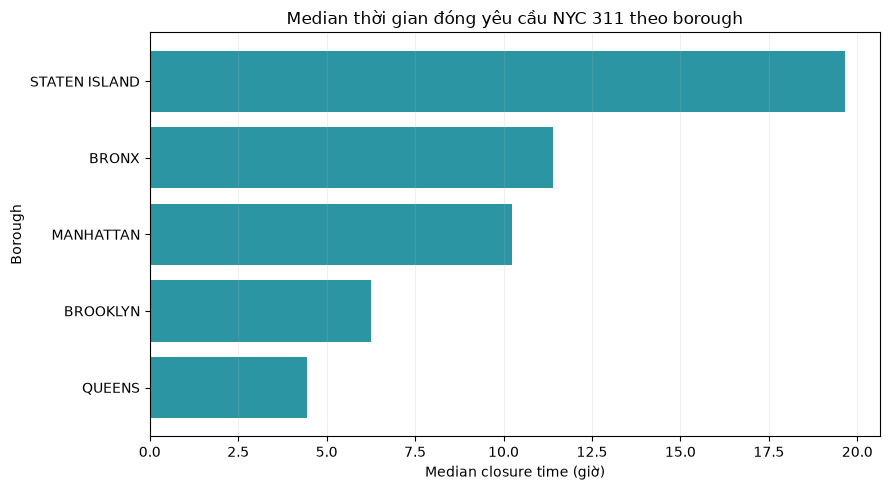

In [56]:
median_plot = (
    borough_closure_summary
    .sort_values(
        "median",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.barh(
    median_plot["borough"],
    median_plot["median"],
    color="#2C95A3"
)

ax.set_xlabel(
    "Median closure time (giờ)"
)
ax.set_ylabel(
    "Borough"
)
ax.set_title(
    "Median thời gian đóng yêu cầu NYC 311 theo borough"
)

ax.grid(
    axis="x",
    alpha=0.20
)

plt.tight_layout()
plt.show()

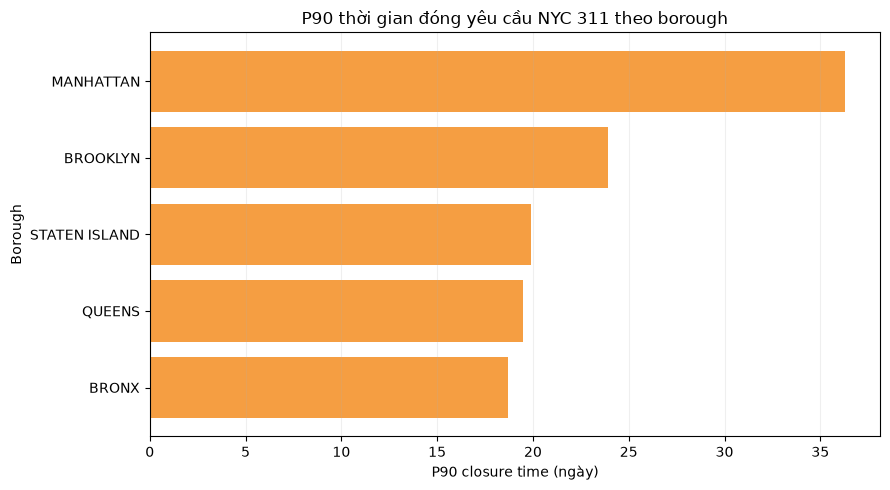

In [57]:
p90_plot = (
    borough_closure_summary
    .sort_values(
        "p90_days",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.barh(
    p90_plot["borough"],
    p90_plot["p90_days"],
    color="#F59E42"
)

ax.set_xlabel(
    "P90 closure time (ngày)"
)
ax.set_ylabel(
    "Borough"
)
ax.set_title(
    "P90 thời gian đóng yêu cầu NYC 311 theo borough"
)

ax.grid(
    axis="x",
    alpha=0.20
)

plt.tight_layout()
plt.show()

**Nhận xét.** Thứ hạng borough thay đổi tùy metric: Staten Island có median cao nhất, trong khi Manhattan nổi bật ở P90. Vì median và P90 phản ánh hai phần khác nhau của phân phối, không nên kết luận borough nào “xử lý kém hơn” chỉ từ một chỉ số; cơ cấu complaint và agency giữa borough cũng khác nhau.

In [58]:
TOP_N_COMPLAINTS = 15

top_complaints = (
    complaint_total
    .head(TOP_N_COMPLAINTS)
    ["complaint_type"]
    .tolist()
)

print(
    "Top complaint types:",
    len(top_complaints)
)

for complaint in top_complaints:
    print("-", complaint)

Top complaint types: 15
- Illegal Parking
- Noise - Residential
- HEAT/HOT WATER
- Blocked Driveway
- Noise - Street/Sidewalk
- UNSANITARY CONDITION
- Street Condition
- Abandoned Vehicle
- Noise - Commercial
- Water System
- PLUMBING
- PAINT/PLASTER
- Dirty Condition
- Noise
- Noise - Vehicle


In [59]:
complaint_closure_parts = []

for file in processed_files:
    part = pd.read_parquet(
        file,
        columns=[
            "complaint_type",
            "created_date",
            "closed_date",
        ],
    )
    part = add_final_closure_fields(part)

    valid = (
        part.loc[
            part["complaint_type"].isin(top_complaints)
            & part["closure_valid_final"],
            ["complaint_type", "closure_hours_final"],
        ]
        .dropna(subset=["closure_hours_final"])
        .rename(columns={"closure_hours_final": "closure_hours"})
    )

    complaint_closure_parts.append(valid)

complaint_closure_data = pd.concat(
    complaint_closure_parts,
    ignore_index=True,
)

complaint_closure_summary = (
    complaint_closure_data
    .groupby("complaint_type")["closure_hours"]
    .agg(requests="count", median="median", mean="mean")
    .reset_index()
)

complaint_p90 = (
    complaint_closure_data
    .groupby("complaint_type")["closure_hours"]
    .quantile(0.90)
    .rename("p90")
    .reset_index()
)

complaint_closure_summary = complaint_closure_summary.merge(
    complaint_p90,
    on="complaint_type",
    how="left",
)

complaint_closure_summary["median_days"] = (
    complaint_closure_summary["median"] / 24
)
complaint_closure_summary["p90_days"] = (
    complaint_closure_summary["p90"] / 24
)

COMPLAINT_CLOSURE_FILE = TABLE_DIR / "complaint_closure_summary.parquet"
complaint_closure_summary.to_parquet(COMPLAINT_CLOSURE_FILE, index=False)

display(
    complaint_closure_summary
    .sort_values("median")
    .round(2)
)

,complaint_type,requests,median,mean,p90,median_days,p90_days
6,Noise - Commercial,261151,0.65,1.49,2.96,0.03,0.12
8,Noise - Street/Sidewalk,636473,0.70,1.64,3.36,0.03,0.14
9,Noise - Vehicle,208008,0.74,1.70,3.63,0.03,0.15
7,Noise - Residential,1517922,0.92,7.62,6.54,0.04,0.27
4,Illegal Parking,1965696,1.21,2.62,5.97,0.05,0.25
1,Blocked Driveway,665195,1.44,2.95,6.52,0.06,0.27
0,Abandoned Vehicle,265651,1.56,3.62,8.28,0.07,0.35
14,Water System,257551,5.00,164.62,224.92,0.21,9.37
12,Street Condition,275796,27.42,77.84,167.01,1.14,6.96
2,Dirty Condition,210310,27.63,92.59,195.74,1.15,8.16


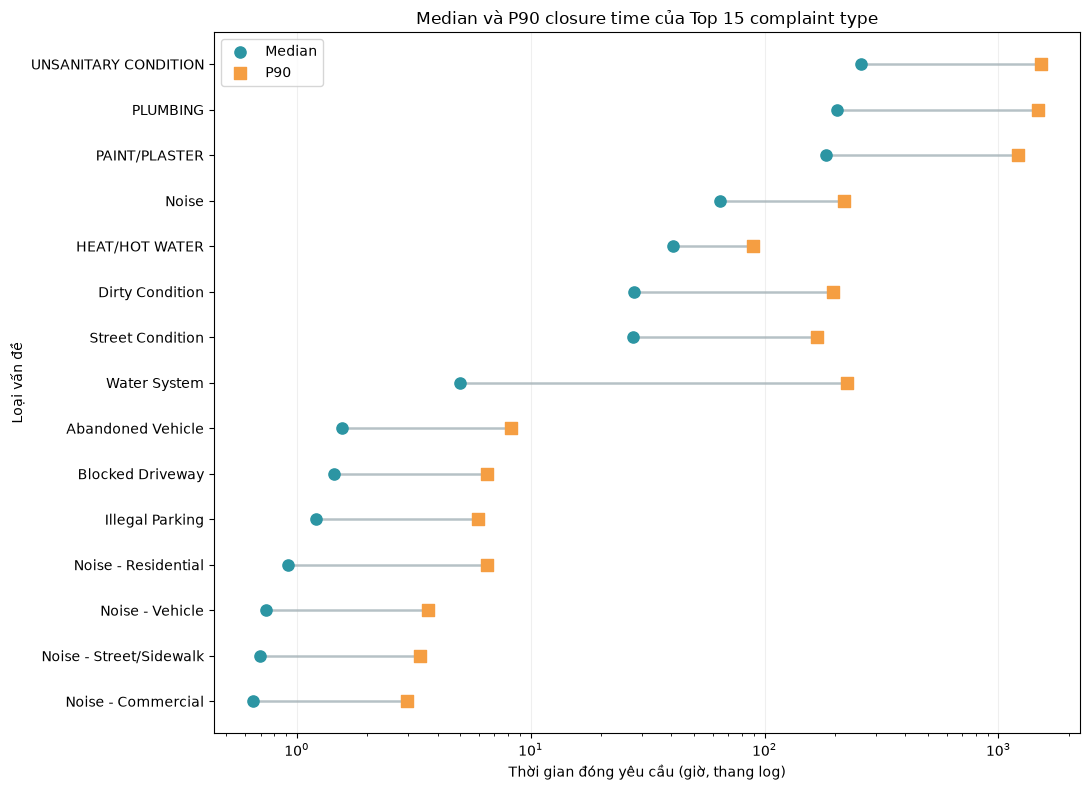

Saved: d:\nyc311_analysis\outputs\charts\complaint_closure_median_p90.png


In [60]:
complaint_plot = (
    complaint_closure_summary
    .sort_values(
        "median",
        ascending=True
    )
    .reset_index(drop=True)
)

fig, ax = plt.subplots(
    figsize=(11, 8)
)

y = np.arange(
    len(complaint_plot)
)

# Connector dùng một màu cố định để không gây nhiễu thị giác
for i, row in complaint_plot.iterrows():
    ax.plot(
        [
            row["median"],
            row["p90"]
        ],
        [
            i,
            i
        ],
        linewidth=1.8,
        color="#AAB7BC",
        alpha=0.85,
        zorder=1
    )

ax.scatter(
    complaint_plot["median"],
    y,
    s=65,
    color="#2C95A3",
    label="Median",
    zorder=3
)

ax.scatter(
    complaint_plot["p90"],
    y,
    s=65,
    marker="s",
    color="#F59E42",
    label="P90",
    zorder=3
)

ax.set_yticks(y)
ax.set_yticklabels(
    complaint_plot[
        "complaint_type"
    ]
)

ax.set_xscale("log")

ax.set_xlabel(
    "Thời gian đóng yêu cầu (giờ, thang log)"
)
ax.set_ylabel(
    "Loại vấn đề"
)
ax.set_title(
    "Median và P90 closure time của Top 15 complaint type"
)

ax.legend()

ax.grid(
    axis="x",
    alpha=0.20
)

plt.tight_layout()

COMPLAINT_CLOSURE_CHART = CHART_DIR / "complaint_closure_median_p90.png"
fig.savefig(COMPLAINT_CLOSURE_CHART, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", COMPLAINT_CLOSURE_CHART)

**Nhận xét.** Nhóm noise và illegal parking có median closure tương đối ngắn, trong khi `PAINT/PLASTER`, `PLUMBING` và `UNSANITARY CONDITION` có median và P90 cao hơn nhiều. Khoảng cách Median→P90 lớn ở một số complaint cho thấy phần đuôi chậm đáng kể; biểu đồ này mô tả đặc tính từng loại request, **không phải bảng xếp hạng hiệu suất agency**.

# 5. CHANNEL — Yêu cầu được gửi qua kênh nào?

In [61]:
CHANNEL_TOTAL_FILE = (
    TABLE_DIR
    / "channel_total.parquet"
)

CHANNEL_YEAR_FILE = (
    TABLE_DIR
    / "channel_by_year.parquet"
)

if (
    CHANNEL_TOTAL_FILE.exists()
    and CHANNEL_YEAR_FILE.exists()
    and not FORCE_REBUILD
):

    print("Loading cached channel tables...")

    channel_total = pd.read_parquet(
        CHANNEL_TOTAL_FILE
    )

    channel_by_year = pd.read_parquet(
        CHANNEL_YEAR_FILE
    )

else:

    print("Building channel tables...")

    channel_parts = []

    for i, file in enumerate(
        processed_files,
        start=1
    ):

        part = pd.read_parquet(
            file,
            columns=[
                "year",
                "open_data_channel_type"
            ]
        )

        agg = (
            part
            .groupby(
                [
                    "year",
                    "open_data_channel_type"
                ],
                dropna=False
            )
            .size()
            .reset_index(
                name="requests"
            )
        )

        channel_parts.append(
            agg
        )

        print(
            f"[{i:02d}/48] {file.name}"
        )

    channel_by_year = (
        pd.concat(
            channel_parts,
            ignore_index=True
        )
        .groupby(
            [
                "year",
                "open_data_channel_type"
            ],
            dropna=False,
            as_index=False
        )["requests"]
        .sum()
    )

    channel_total = (
        channel_by_year
        .groupby(
            "open_data_channel_type",
            dropna=False,
            as_index=False
        )["requests"]
        .sum()
        .sort_values(
            "requests",
            ascending=False
        )
        .reset_index(drop=True)
    )

    channel_total[
        "share_pct"
    ] = (
        channel_total["requests"]
        / channel_total["requests"].sum()
        * 100
    )

    channel_total.to_parquet(
        CHANNEL_TOTAL_FILE,
        index=False
    )

    channel_by_year.to_parquet(
        CHANNEL_YEAR_FILE,
        index=False
    )

Building channel tables...
[01/48] nyc311_2022_01_processed.parquet
[02/48] nyc311_2022_02_processed.parquet
[03/48] nyc311_2022_03_processed.parquet
[04/48] nyc311_2022_04_processed.parquet
[05/48] nyc311_2022_05_processed.parquet
[06/48] nyc311_2022_06_processed.parquet
[07/48] nyc311_2022_07_processed.parquet
[08/48] nyc311_2022_08_processed.parquet
[09/48] nyc311_2022_09_processed.parquet
[10/48] nyc311_2022_10_processed.parquet
[11/48] nyc311_2022_11_processed.parquet
[12/48] nyc311_2022_12_processed.parquet
[13/48] nyc311_2023_01_processed.parquet
[14/48] nyc311_2023_02_processed.parquet
[15/48] nyc311_2023_03_processed.parquet
[16/48] nyc311_2023_04_processed.parquet
[17/48] nyc311_2023_05_processed.parquet
[18/48] nyc311_2023_06_processed.parquet
[19/48] nyc311_2023_07_processed.parquet
[20/48] nyc311_2023_08_processed.parquet
[21/48] nyc311_2023_09_processed.parquet
[22/48] nyc311_2023_10_processed.parquet
[23/48] nyc311_2023_11_processed.parquet
[24/48] nyc311_2023_12_process

In [62]:
display(
    channel_total.round({
        "share_pct": 2
    })
)

print(
    "Total requests:",
    f"{channel_total['requests'].sum():,}"
)

print(
    "Number of channel categories:",
    channel_total[
        "open_data_channel_type"
    ].nunique(
        dropna=False
    )
)

,open_data_channel_type,requests,share_pct
0,ONLINE,5771249,42.73
1,PHONE,3792938,28.08
2,MOBILE,2868961,21.24
3,UNKNOWN,1072807,7.94
4,OTHER,539,0.00


Total requests: 13,506,494
Number of channel categories: 5


In [63]:
channel_year_share = (
    channel_by_year
    .copy()
)

channel_year_share[
    "year_total"
] = (
    channel_year_share
    .groupby("year")
    ["requests"]
    .transform("sum")
)

channel_year_share[
    "share_pct"
] = (
    channel_year_share["requests"]
    / channel_year_share["year_total"]
    * 100
)

display(
    channel_year_share
    .sort_values(
        ["year", "requests"],
        ascending=[True, False]
    )
    .round({
        "share_pct": 2
    })
)

,year,open_data_channel_type,requests,year_total,share_pct
1,2022,ONLINE,1437740,3169960,45.36
3,2022,PHONE,782415,3169960,24.68
0,2022,MOBILE,661255,3169960,20.86
4,2022,UNKNOWN,288375,3169960,9.10
2,2022,OTHER,175,3169960,0.01
6,2023,ONLINE,1385201,3224723,42.96
8,2023,PHONE,972139,3224723,30.15
5,2023,MOBILE,613817,3224723,19.03
9,2023,UNKNOWN,253317,3224723,7.86
7,2023,OTHER,249,3224723,0.01


In [64]:
channel_share_pivot = (
    channel_year_share
    .pivot(
        index="year",
        columns="open_data_channel_type",
        values="share_pct"
    )
    .fillna(0)
)

display(
    channel_share_pivot.round(2)
)

open_data_channel_type,MOBILE,ONLINE,OTHER,PHONE,UNKNOWN
year,,,,,
2022,20.86,45.36,0.01,24.68,9.10
2023,19.03,42.96,0.01,30.15,7.86
2024,21.34,40.02,0.00,30.91,7.72
2025,23.42,42.81,0.00,26.54,7.23


In [65]:
print(
    "Share sum by year:"
)

display(
    channel_share_pivot
    .sum(axis=1)
    .round(6)
)

Share sum by year:


year
2022    100.0
2023    100.0
2024    100.0
2025    100.0
dtype: float64

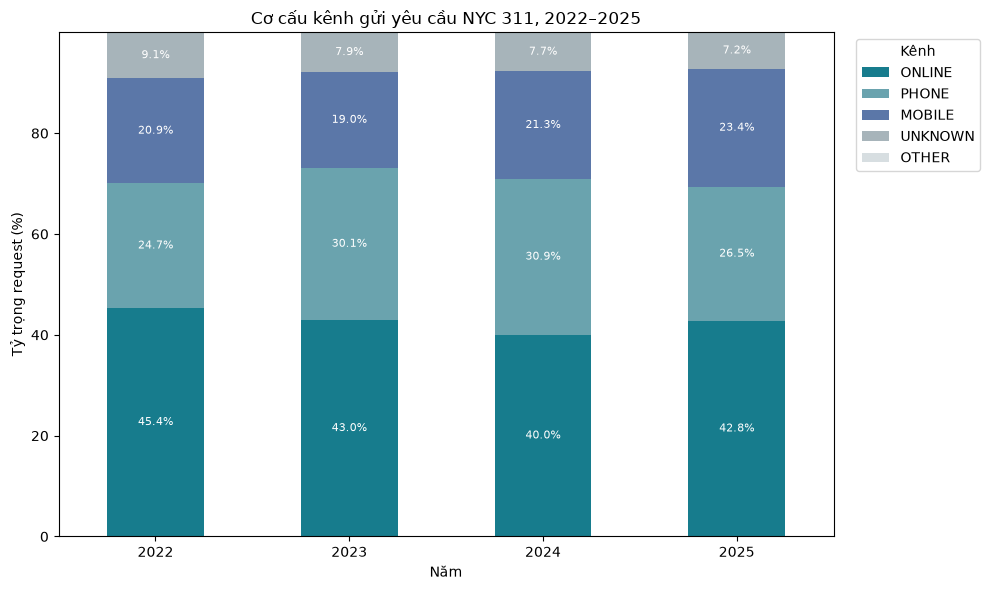

In [66]:
channel_order = [
    "ONLINE",
    "PHONE",
    "MOBILE",
    "UNKNOWN",
    "OTHER"
]

channel_plot = (
    channel_share_pivot[
        channel_order
    ]
)

ax = channel_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=[
        "#177C8D",
        "#6AA3AE",
        "#5B77A8",
        "#A7B4BA",
        "#D7DEE1"
    ]
)

ax.set_xlabel(
    "Năm"
)
ax.set_ylabel(
    "Tỷ trọng request (%)"
)
ax.set_title(
    "Cơ cấu kênh gửi yêu cầu NYC 311, 2022–2025"
)

ax.legend(
    title="Kênh",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

# Nhãn trực tiếp cho segment đủ lớn để đọc
for container in ax.containers:
    labels = [
        (
            f"{bar.get_height():.1f}%"
            if bar.get_height() >= 4
            else ""
        )
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=8,
        color="white"
    )

plt.xticks(
    rotation=0
)

plt.tight_layout()
plt.show()

In [67]:
CHANNEL_YEAR_SHARE_FILE = (
    TABLE_DIR
    / "channel_year_share.parquet"
)

channel_year_share.to_parquet(
    CHANNEL_YEAR_SHARE_FILE,
    index=False
)

print(
    "Saved:",
    CHANNEL_YEAR_SHARE_FILE
)

Saved: d:\nyc311_analysis\outputs\tables\channel_year_share.parquet


**Nhận xét.** `ONLINE` là kênh lớn nhất trong toàn giai đoạn, trong khi `MOBILE` tăng tỷ trọng vào 2025. Nếu cộng ONLINE + MOBILE, kênh số chiếm khoảng **66,2% request năm 2025**. `UNKNOWN` được giữ như một category nguồn quan sát được thay vì tự động coi là missing.

# 6. AGENCY — Cơ quan nào tiếp nhận nhiều yêu cầu?

`agency` là chiều dữ liệu cốt lõi của hệ thống dịch vụ công. Phần này chỉ so sánh **khối lượng request**, không dùng số lượng để đánh giá chất lượng hay hiệu suất của cơ quan vì mỗi agency phụ trách nhóm vấn đề khác nhau.

In [68]:
AGENCY_FILE = (
    TABLE_DIR
    / "agency_requests.parquet"
)

if (
    AGENCY_FILE.exists()
    and not FORCE_REBUILD
):
    agency_requests = pd.read_parquet(
        AGENCY_FILE
    )
else:
    agency_parts = []

    for i, file in enumerate(
        processed_files,
        start=1
    ):
        part = pd.read_parquet(
            file,
            columns=[
                "agency",
                "agency_name"
            ]
        )

        temp = (
            part
            .dropna(
                subset=["agency"]
            )
            .groupby(
                [
                    "agency",
                    "agency_name"
                ],
                dropna=False
            )
            .size()
            .reset_index(
                name="requests"
            )
        )

        agency_parts.append(
            temp
        )

        print(
            f"[{i:02d}/48] "
            f"{file.name}"
        )

    agency_requests = (
        pd.concat(
            agency_parts,
            ignore_index=True
        )
        .groupby(
            [
                "agency",
                "agency_name"
            ],
            dropna=False,
            as_index=False
        )["requests"]
        .sum()
        .sort_values(
            "requests",
            ascending=False
        )
        .reset_index(drop=True)
    )

    agency_requests.to_parquet(
        AGENCY_FILE,
        index=False
    )

agency_requests[
    "share_pct"
] = (
    agency_requests["requests"]
    / agency_requests["requests"].sum()
    * 100
)

display(
    agency_requests
    .head(10)
    .round({
        "share_pct": 2
    })
)

[01/48] nyc311_2022_01_processed.parquet
[02/48] nyc311_2022_02_processed.parquet
[03/48] nyc311_2022_03_processed.parquet
[04/48] nyc311_2022_04_processed.parquet
[05/48] nyc311_2022_05_processed.parquet
[06/48] nyc311_2022_06_processed.parquet
[07/48] nyc311_2022_07_processed.parquet
[08/48] nyc311_2022_08_processed.parquet
[09/48] nyc311_2022_09_processed.parquet
[10/48] nyc311_2022_10_processed.parquet
[11/48] nyc311_2022_11_processed.parquet
[12/48] nyc311_2022_12_processed.parquet
[13/48] nyc311_2023_01_processed.parquet
[14/48] nyc311_2023_02_processed.parquet
[15/48] nyc311_2023_03_processed.parquet
[16/48] nyc311_2023_04_processed.parquet
[17/48] nyc311_2023_05_processed.parquet
[18/48] nyc311_2023_06_processed.parquet
[19/48] nyc311_2023_07_processed.parquet
[20/48] nyc311_2023_08_processed.parquet
[21/48] nyc311_2023_09_processed.parquet
[22/48] nyc311_2023_10_processed.parquet
[23/48] nyc311_2023_11_processed.parquet
[24/48] nyc311_2023_12_processed.parquet
[25/48] nyc311_2

,agency,agency_name,requests,share_pct
0,NYPD,New York City Police Department,6041173,44.73
1,HPD,Department of Housing Preservation and Develop...,2857262,21.15
2,DSNY,Department of Sanitation,1240214,9.18
3,DOT,Department of Transportation,849060,6.29
4,DEP,Department of Environmental Protection,727510,5.39
5,DPR,Department of Parks and Recreation,488145,3.61
6,DOB,Department of Buildings,398904,2.95
7,DOHMH,Department of Health and Mental Hygiene,342409,2.54
8,DHS,Department of Homeless Services,196522,1.46
9,TLC,Taxi and Limousine Commission,139931,1.04


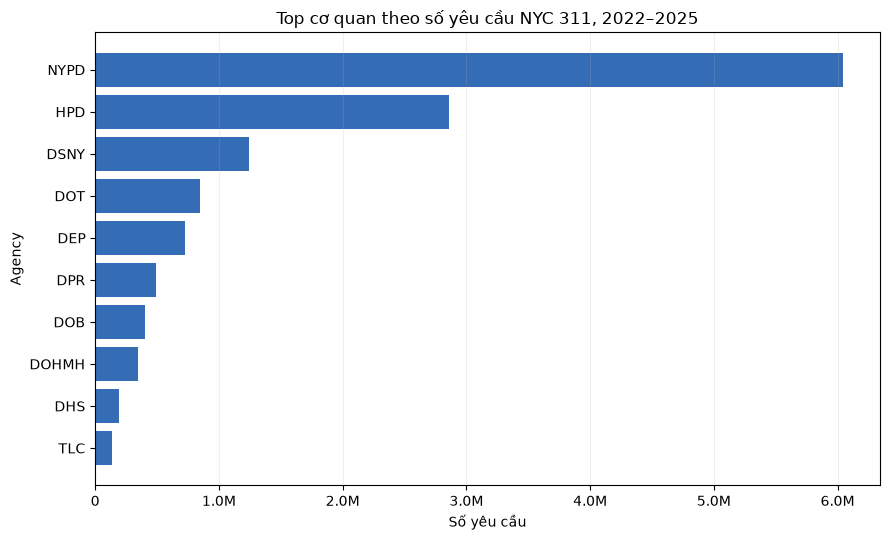

Agency có volume lớn nhất: NYPD - New York City Police Department (6,041,173 requests, 44.7%)


In [69]:
agency_plot = (
    agency_requests
    .head(10)
    .sort_values(
        "requests",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

ax.barh(
    agency_plot["agency"],
    agency_plot["requests"],
    color="#356CB6"
)

ax.xaxis.set_major_formatter(
    MILLION_FORMATTER
)

ax.set_xlabel(
    "Số yêu cầu"
)
ax.set_ylabel(
    "Agency"
)
ax.set_title(
    "Top cơ quan theo số yêu cầu NYC 311, 2022–2025"
)

ax.grid(
    axis="x",
    alpha=0.20
)

plt.tight_layout()
plt.show()

top_agency = (
    agency_requests.iloc[0]
)

print(
    f"Agency có volume lớn nhất: "
    f"{top_agency['agency']} - "
    f"{top_agency['agency_name']} "
    f"({top_agency['requests']:,} requests, "
    f"{top_agency['share_pct']:.1f}%)"
)

## Bổ sung cho Q6 — Cơ cấu loại phản ánh của các agency lớn

Số lượng request chỉ cho biết quy mô công việc. Để giải thích vì sao không nên so trực tiếp các agency bằng một KPI closure chung, phần dưới xem `complaint_type` chiếm tỷ trọng lớn trong từng agency.

In [70]:
TOP_AGENCIES_N = 5
top_agencies = agency_requests.head(TOP_AGENCIES_N)["agency"].tolist()

agency_complaint_parts = []

for i, file in enumerate(processed_files, start=1):
    part = pd.read_parquet(
        file,
        columns=["agency", "complaint_type"],
    ).dropna(subset=["agency", "complaint_type"])

    part = part[part["agency"].isin(top_agencies)]

    if part.empty:
        continue

    temp = (
        part.groupby(["agency", "complaint_type"], as_index=False)
        .size()
        .rename(columns={"size": "requests"})
    )
    agency_complaint_parts.append(temp)

agency_complaint = (
    pd.concat(agency_complaint_parts, ignore_index=True)
    .groupby(["agency", "complaint_type"], as_index=False)["requests"]
    .sum()
)

agency_totals = (
    agency_complaint.groupby("agency", as_index=False)["requests"]
    .sum()
    .rename(columns={"requests": "agency_total"})
)

agency_complaint = agency_complaint.merge(
    agency_totals,
    on="agency",
    how="left",
)

agency_complaint["share_within_agency_pct"] = (
    agency_complaint["requests"] / agency_complaint["agency_total"] * 100
)

agency_top_complaints = (
    agency_complaint
    .sort_values(
        ["agency", "requests"],
        ascending=[True, False],
    )
    .groupby("agency", as_index=False)
    .head(3)
    .reset_index(drop=True)
)

AGENCY_COMPLAINT_FILE = TABLE_DIR / "agency_complaint_mix.parquet"
agency_complaint.to_parquet(AGENCY_COMPLAINT_FILE, index=False)

display(
    agency_top_complaints[
        [
            "agency",
            "complaint_type",
            "requests",
            "share_within_agency_pct",
        ]
    ].round({"share_within_agency_pct": 2})
)

,agency,complaint_type,requests,share_within_agency_pct
0,DEP,Water System,260013,35.74
1,DEP,Noise,211753,29.11
2,DEP,Sewer,110589,15.20
3,DOT,Street Condition,284706,33.53
4,DOT,Traffic Signal Condition,171722,20.22
5,DOT,Street Light Condition,156438,18.42
6,DSNY,Dirty Condition,212268,17.12
7,DSNY,Derelict Vehicles,191680,15.46
8,DSNY,Missed Collection,187281,15.10
9,HPD,HEAT/HOT WATER,1074595,37.61


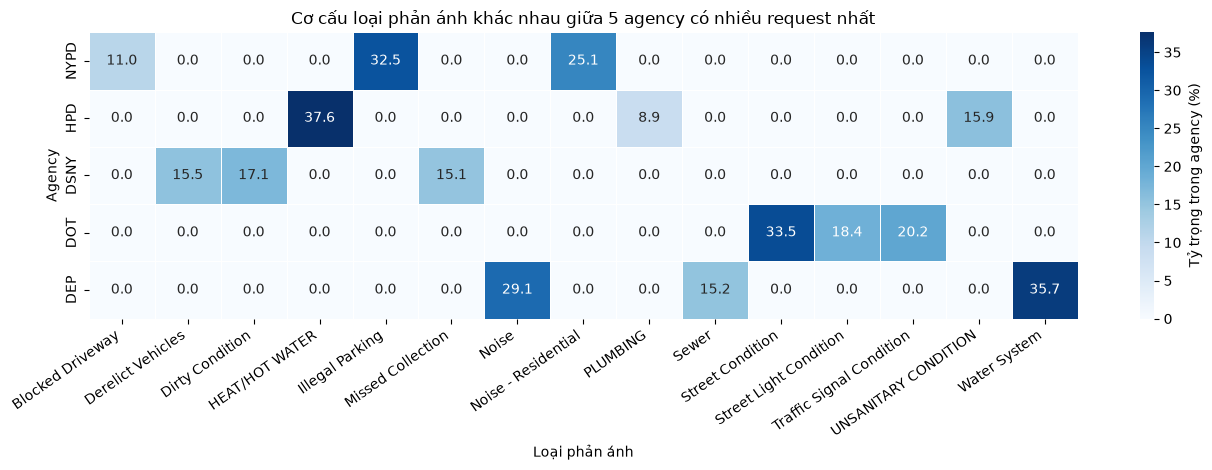

Saved: d:\nyc311_analysis\outputs\charts\agency_complaint_mix.png


In [71]:
# Heatmap dùng union của Top 3 complaint trong 5 agency lớn.
mix_complaints = (
    agency_top_complaints["complaint_type"]
    .drop_duplicates()
    .tolist()
)

agency_mix_matrix = (
    agency_complaint[
        agency_complaint["complaint_type"].isin(mix_complaints)
    ]
    .pivot(
        index="agency",
        columns="complaint_type",
        values="share_within_agency_pct",
    )
    .fillna(0)
    .reindex(top_agencies)
)

fig, ax = plt.subplots(
    figsize=(max(11, 0.9 * len(mix_complaints)), 4.8)
)

sns.heatmap(
    agency_mix_matrix,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.4,
    cbar_kws={"label": "Tỷ trọng trong agency (%)"},
    ax=ax,
)

ax.set_xlabel("Loại phản ánh")
ax.set_ylabel("Agency")
ax.set_title("Cơ cấu loại phản ánh khác nhau giữa 5 agency có nhiều request nhất")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

AGENCY_MIX_CHART = CHART_DIR / "agency_complaint_mix.png"
fig.savefig(AGENCY_MIX_CHART, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", AGENCY_MIX_CHART)

**diễn giải.** Agency có nhiều request hơn không đồng nghĩa xử lý kém hơn; volume phụ thuộc phạm vi nhiệm vụ và loại complaint mà cơ quan đó phụ trách. Nếu muốn so sánh closure giữa agency, cần kiểm soát `complaint_type` hoặc phân tích trong cùng một nhóm dịch vụ để tránh so sánh không tương đồng.

# 7. Kết luận tạm trước phần deep-dive

Các kết luận tổng chỉ có ý nghĩa khi được kiểm tra ở mức chi tiết hơn:

- Tổng request tăng nhưng cần xem **nhóm nào đóng góp** vào phần tăng và nhóm nào giảm.
- Mẫu thời gian tổng có thể che khác biệt rất lớn giữa các `complaint_type`.
- Count địa lý phù hợp để đọc workload, còn tỷ lệ theo dân số phù hợp để so mức sử dụng tương đối.
- Closure time phải đọc bằng nhiều thước đo vì phân phối lệch phải và có right-censoring.
- Agency volume phải đọc cùng service mix, không dùng độc lập như thước đo hiệu suất.

Phần deep-dive phía dưới cung cấp các bằng chứng còn thiếu cho các kết luận này.


# 8. DEEP-DIVE — Từ mô tả sang kể chuyện bằng dữ liệu

Phần bổ sung này trả lời sâu hơn ba điểm mà các biểu đồ tổng quan chưa giải thích được:

1. Mùa vụ có giống nhau giữa các `complaint_type` hay không?
2. Mẫu theo thứ × giờ có khác nhau giữa các loại yêu cầu hay không?
3. Thứ hạng không gian thay đổi thế nào khi chuyển từ **count tuyệt đối** sang **chuẩn hóa theo dân số**?

Các biểu đồ trong phần này được thiết kế theo hướng *comparison-first*: dùng cùng thang đo khi có thể, small multiples thay vì chồng quá nhiều đường, và dùng position/length làm kênh mã hóa chính cho so sánh định lượng.

## 8.1 Mùa vụ theo từng loại yêu cầu — small multiples

Biểu đồ seasonality tổng toàn thành phố có thể che khuất các cơ chế khác nhau giữa các loại request.  
Phần này chọn ba nhóm lớn có đặc tính khác nhau:

- `HEAT/HOT WATER`
- `Noise - Residential`
- `Illegal Parking`

Mỗi panel dùng **Seasonality Index riêng của complaint**, trong đó 100 là daily rate trung bình của complaint đó trong năm tương ứng. Vì vậy có thể so sánh hình dạng mùa vụ mà không bị quy mô tuyệt đối chi phối.

In [72]:
# Build complaint-month table for selected complaint types.
SELECTED_COMPLAINTS = [
    "HEAT/HOT WATER",
    "Noise - Residential",
    "Illegal Parking",
]

complaint_month_parts = []

for i, file in enumerate(processed_files, start=1):
    part = pd.read_parquet(
        file,
        columns=["created_date", "year", "month", "complaint_type"],
    )

    part = part[
        part["complaint_type"].isin(SELECTED_COMPLAINTS)
    ].copy()

    if part.empty:
        continue

    temp = (
        part.groupby(
            ["year", "month", "complaint_type"],
            as_index=False,
        )
        .size()
        .rename(columns={"size": "requests"})
    )

    complaint_month_parts.append(temp)

complaint_month = (
    pd.concat(complaint_month_parts, ignore_index=True)
    .groupby(
        ["year", "month", "complaint_type"],
        as_index=False,
    )["requests"]
    .sum()
)

complaint_month["days_in_month"] = pd.to_datetime(
    dict(
        year=complaint_month["year"],
        month=complaint_month["month"],
        day=1,
    )
).dt.days_in_month

complaint_month["avg_daily_requests"] = (
    complaint_month["requests"]
    / complaint_month["days_in_month"]
)

complaint_year_baseline = (
    complaint_month
    .groupby(["year", "complaint_type"], as_index=False)
    .agg(
        total_requests=("requests", "sum"),
        total_days=("days_in_month", "sum"),
    )
)

complaint_year_baseline["yearly_avg_daily"] = (
    complaint_year_baseline["total_requests"]
    / complaint_year_baseline["total_days"]
)

complaint_month = complaint_month.merge(
    complaint_year_baseline[
        ["year", "complaint_type", "yearly_avg_daily"]
    ],
    on=["year", "complaint_type"],
    how="left",
)

complaint_month["seasonality_index"] = (
    complaint_month["avg_daily_requests"]
    / complaint_month["yearly_avg_daily"]
    * 100
)

COMPLAINT_SEASONALITY_FILE = (
    TABLE_DIR / "complaint_monthly_seasonality.parquet"
)

complaint_month.to_parquet(
    COMPLAINT_SEASONALITY_FILE,
    index=False,
)

display(
    complaint_month.sort_values(
        ["complaint_type", "year", "month"]
    ).round(1)
)

,year,month,complaint_type,requests,days_in_month,avg_daily_requests,yearly_avg_daily,seasonality_index
0,2022,1,HEAT/HOT WATER,62026,31,2000.8,724.4,276.2
3,2022,2,HEAT/HOT WATER,30126,28,1075.9,724.4,148.5
6,2022,3,HEAT/HOT WATER,23780,31,767.1,724.4,105.9
9,2022,4,HEAT/HOT WATER,16138,30,537.9,724.4,74.3
12,2022,5,HEAT/HOT WATER,7040,31,227.1,724.4,31.4
...,...,...,...,...,...,...,...,...
131,2025,8,Noise - Residential,32756,31,1056.6,1269.4,83.2
134,2025,9,Noise - Residential,36142,30,1204.7,1269.4,94.9
137,2025,10,Noise - Residential,49182,31,1586.5,1269.4,125.0
140,2025,11,Noise - Residential,43928,30,1464.3,1269.4,115.3


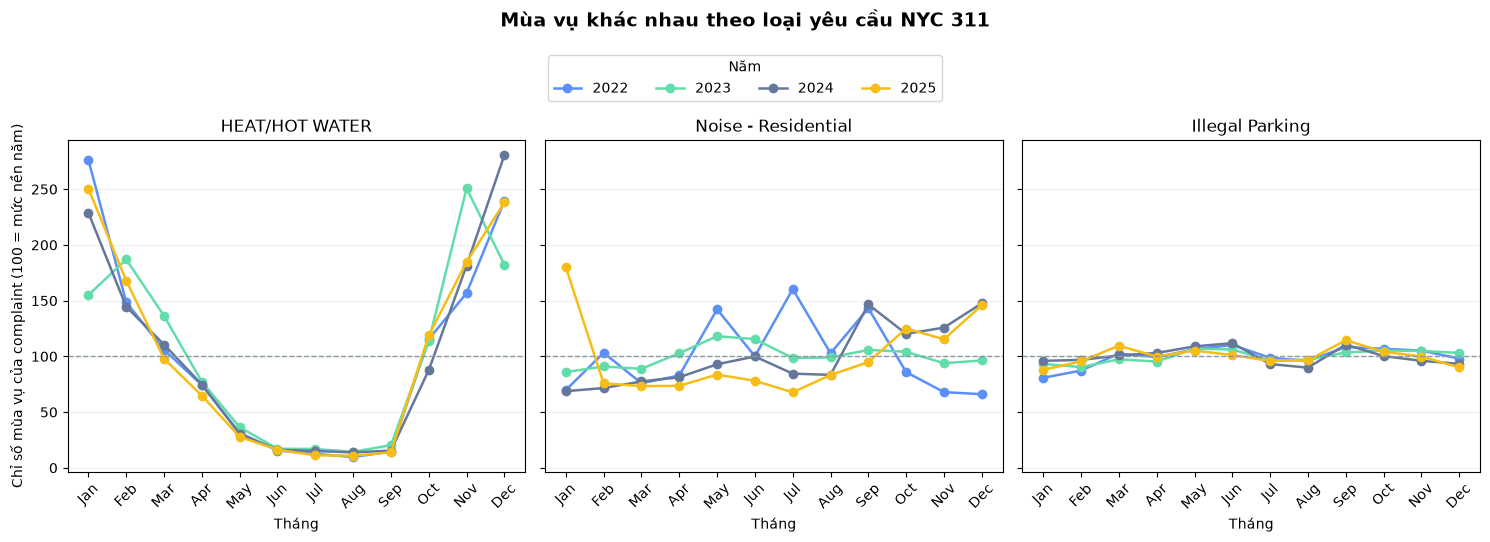

Saved: d:\nyc311_analysis\outputs\charts\complaint_seasonality_small_multiples.png


In [73]:
# Small multiples: one complaint per panel, same y-scale.
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.8),
    sharey=True,
)

year_colors = {
    2022: "#5B8FF9",
    2023: "#61DDAA",
    2024: "#65789B",
    2025: "#F6BD16",
}

for ax, complaint in zip(axes, SELECTED_COMPLAINTS):
    temp = complaint_month[
        complaint_month["complaint_type"] == complaint
    ]

    pivot = temp.pivot(
        index="month",
        columns="year",
        values="seasonality_index",
    )

    for year in pivot.columns:
        ax.plot(
            pivot.index,
            pivot[year],
            marker="o",
            linewidth=1.8,
            label=str(year),
            color=year_colors.get(year),
        )

    ax.axhline(
        100,
        color="#8A9AA0",
        linestyle="--",
        linewidth=1,
    )

    ax.set_title(complaint)
    ax.set_xticks(
        range(1, 13),
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
        rotation=45,
    )
    ax.set_xlabel("Tháng")
    ax.grid(axis="y", alpha=0.18)

axes[0].set_ylabel(
    "Chỉ số mùa vụ của complaint (100 = mức nền năm)"
)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title="Năm",
    loc="upper center",
    ncol=4,
    bbox_to_anchor=(0.5, 1.04),
)

fig.suptitle(
    "Mùa vụ khác nhau theo loại yêu cầu NYC 311",
    y=1.12,
    fontsize=14,
    fontweight="bold",
)

plt.tight_layout()

SEASONALITY_CHART = (
    CHART_DIR / "complaint_seasonality_small_multiples.png"
)
fig.savefig(
    SEASONALITY_CHART,
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print("Saved:", SEASONALITY_CHART)


 Nếu ba panel có hình dạng khác nhau, kết luận “NYC 311 có một mùa vụ chung” là quá đơn giản.  
Trong báo cáo nên dẫn trực tiếp các tháng có độ lệch lớn nhất của từng complaint, đặc biệt kiểm tra January 2023 và January 2025 để xác định nhóm nào đóng góp vào chênh lệch của seasonality toàn hệ thống.

## 8.2 Thứ × giờ theo complaint — hai heatmap có thể so sánh

Heatmap tổng có peak quanh giờ hành chính nhưng không cho biết peak đó đến từ loại yêu cầu nào.  
Để tránh việc complaint có volume lớn tự động có màu đậm hơn, heatmap dưới đây dùng **index tương đối**:

\[
\text{Index}_{d,h}
=
\frac{\text{average requests at weekday-hour }(d,h)}
{\text{overall average weekday-hour requests of the complaint}}
\times 100
\]

Nhờ đó hai complaint khác quy mô vẫn so sánh được pattern.

In [74]:
HEATMAP_COMPLAINTS = [
    "Noise - Residential",
    "Illegal Parking",
]

# Calendar days in the analysis period.
analysis_dates = pd.date_range(
    "2022-01-01",
    "2025-12-31",
    freq="D",
)

complaint_hour_parts = []

for i, file in enumerate(processed_files, start=1):
    part = pd.read_parquet(
        file,
        columns=["created_date", "complaint_type"],
    )

    part = part[
        part["complaint_type"].isin(HEATMAP_COMPLAINTS)
    ].copy()

    if part.empty:
        continue

    part["date"] = part["created_date"].dt.normalize()
    part["hour"] = part["created_date"].dt.hour

    temp = (
        part.groupby(
            ["complaint_type", "date", "hour"],
            as_index=False,
        )
        .size()
        .rename(columns={"size": "requests"})
    )

    complaint_hour_parts.append(temp)

observed = pd.concat(
    complaint_hour_parts,
    ignore_index=True,
)

# Fill zero-count date-hour slots so the mean is a real calendar average.
full_index = pd.MultiIndex.from_product(
    [
        HEATMAP_COMPLAINTS,
        analysis_dates,
        range(24),
    ],
    names=["complaint_type", "date", "hour"],
)

full = (
    observed
    .set_index(["complaint_type", "date", "hour"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

full["weekday_num"] = full["date"].dt.dayofweek

complaint_weekday_hour = (
    full
    .groupby(
        ["complaint_type", "weekday_num", "hour"],
        as_index=False,
    )["requests"]
    .mean()
    .rename(columns={"requests": "avg_requests"})
)

complaint_weekday_hour["complaint_mean"] = (
    complaint_weekday_hour
    .groupby("complaint_type")["avg_requests"]
    .transform("mean")
)

complaint_weekday_hour["relative_index"] = (
    complaint_weekday_hour["avg_requests"]
    / complaint_weekday_hour["complaint_mean"]
    * 100
)

COMPLAINT_WEEKDAY_HOUR_FILE = (
    TABLE_DIR / "complaint_weekday_hour_avg.parquet"
)

complaint_weekday_hour.to_parquet(
    COMPLAINT_WEEKDAY_HOUR_FILE,
    index=False,
)

display(
    complaint_weekday_hour
    .sort_values(
        ["complaint_type", "relative_index"],
        ascending=[True, False],
    )
    .groupby("complaint_type")
    .head(10)
    .round(1)
)

,complaint_type,weekday_num,hour,avg_requests,complaint_mean,relative_index
80,Illegal Parking,3,8,96.3,56.1,171.8
32,Illegal Parking,1,8,95.8,56.1,170.9
104,Illegal Parking,4,8,92.1,56.1,164.4
81,Illegal Parking,3,9,90.9,56.1,162.1
56,Illegal Parking,2,8,90.6,56.1,161.5
8,Illegal Parking,0,8,89.8,56.1,160.1
33,Illegal Parking,1,9,89.4,56.1,159.4
105,Illegal Parking,4,9,87.2,56.1,155.5
9,Illegal Parking,0,9,86.9,56.1,155.0
57,Illegal Parking,2,9,82.9,56.1,148.0


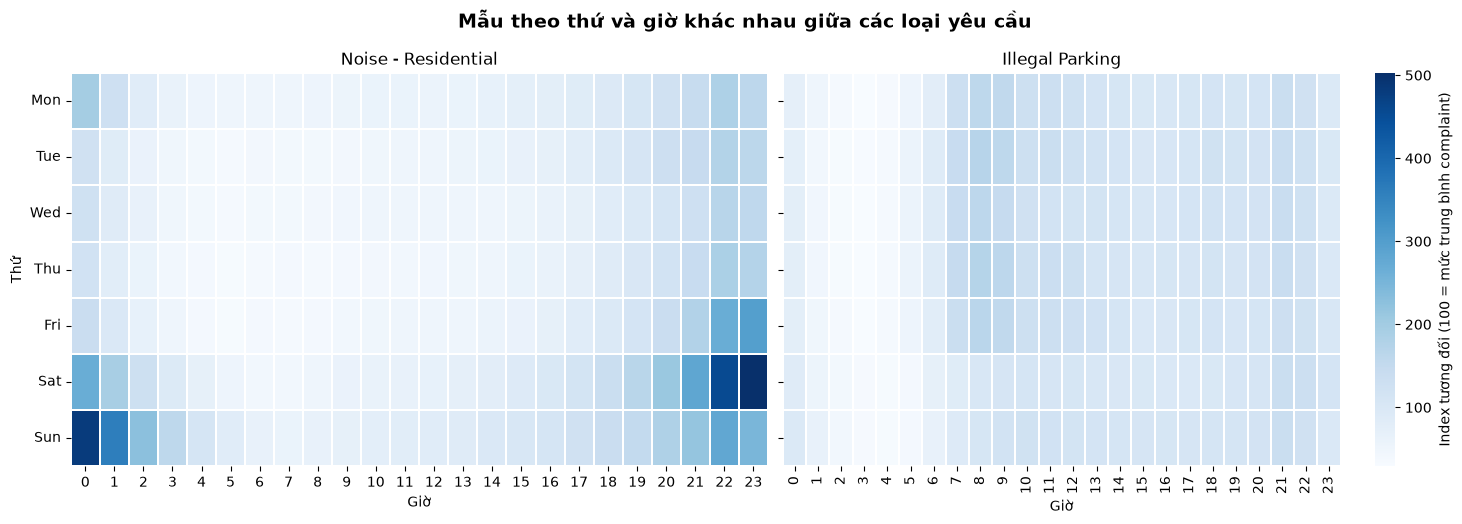

Saved: d:\nyc311_analysis\outputs\charts\complaint_weekday_hour_heatmaps.png


In [75]:
weekday_labels = [
    "Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"
]

matrices = {}

for complaint in HEATMAP_COMPLAINTS:
    matrices[complaint] = (
        complaint_weekday_hour[
            complaint_weekday_hour["complaint_type"] == complaint
        ]
        .pivot(
            index="weekday_num",
            columns="hour",
            values="relative_index",
        )
        .reindex(range(7))
    )

vmin = min(matrix.min().min() for matrix in matrices.values())
vmax = max(matrix.max().max() for matrix in matrices.values())

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5.3),
    sharey=True,
)

for ax, complaint in zip(axes, HEATMAP_COMPLAINTS):
    sns.heatmap(
        matrices[complaint],
        cmap="Blues",
        vmin=vmin,
        vmax=vmax,
        linewidths=0.2,
        cbar=ax is axes[-1],
        cbar_kws={
            "label": "Index tương đối (100 = mức trung bình complaint)"
        } if ax is axes[-1] else None,
        ax=ax,
    )

    ax.set_title(complaint)
    ax.set_xlabel("Giờ")
    ax.set_ylabel("")
    ax.set_yticklabels(
        weekday_labels,
        rotation=0,
    )

axes[0].set_ylabel("Thứ")

fig.suptitle(
    "Mẫu theo thứ và giờ khác nhau giữa các loại yêu cầu",
    fontsize=14,
    fontweight="bold",
)

plt.tight_layout()

HEATMAP_CHART = (
    CHART_DIR / "complaint_weekday_hour_heatmaps.png"
)

fig.savefig(
    HEATMAP_CHART,
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print("Saved:", HEATMAP_CHART)

## 8.3 Borough × loại phản ánh theo 1.000 dân

Heatmap tỷ trọng trong Borough trả lời câu hỏi về **cơ cấu**, nhưng không giải thích loại phản ánh nào đóng góp vào mức request trên dân số cao của Bronx. Phần này đổi mẫu số sang dân số Census 2020 và biểu diễn số request trên 1.000 cư dân tham chiếu cho từng `complaint_type × Borough`.

In [76]:
TOP_RATE_COMPLAINTS_N = 8
rate_complaints = (
    complaint_total.head(TOP_RATE_COMPLAINTS_N)["complaint_type"].tolist()
)

borough_complaint_rate = (
    borough_complaint[
        borough_complaint["complaint_type"].isin(rate_complaints)
    ]
    .merge(
        borough_population_2020,
        on="borough",
        how="left",
        validate="many_to_one",
    )
)

borough_complaint_rate["requests_per_1000"] = (
    borough_complaint_rate["requests"]
    / borough_complaint_rate["population_2020"]
    * 1000
)

BOROUGH_COMPLAINT_RATE_FILE = (
    TABLE_DIR / "borough_complaint_per_1000.parquet"
)
borough_complaint_rate.to_parquet(
    BOROUGH_COMPLAINT_RATE_FILE,
    index=False,
)

borough_rate_matrix = (
    borough_complaint_rate
    .pivot(
        index="borough",
        columns="complaint_type",
        values="requests_per_1000",
    )
    .reindex(
        [
            "BRONX",
            "BROOKLYN",
            "MANHATTAN",
            "QUEENS",
            "STATEN ISLAND",
        ]
    )
    .reindex(columns=rate_complaints)
)

display(borough_rate_matrix.round(1))

complaint_type,Illegal Parking,Noise - Residential,HEAT/HOT WATER,Blocked Driveway,Noise - Street/Sidewalk,UNSANITARY CONDITION,Street Condition,Abandoned Vehicle
borough,,,,,,,,
BRONX,207.1,400.3,262.5,71.8,120.0,102.6,20.6,24.6
BROOKLYN,273.2,133.5,103.0,89.2,54.4,50.1,26.9,32.5
MANHATTAN,153.8,144.8,147.3,10.7,122.2,53.9,28.6,7.3
QUEENS,247.5,116.5,60.1,116.3,40.1,26.1,42.6,45.6
STATEN ISLAND,112.9,75.4,24.3,34.9,14.8,22.5,59.2,36.7


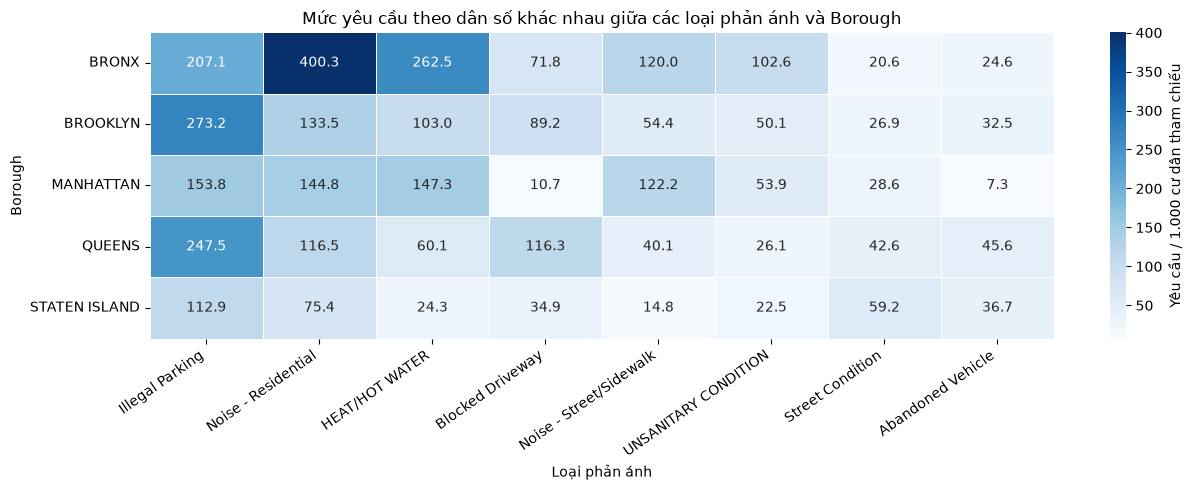

Saved: d:\nyc311_analysis\outputs\charts\borough_complaint_per_1000_heatmap.png


In [77]:
fig, ax = plt.subplots(figsize=(13, 5))

sns.heatmap(
    borough_rate_matrix,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.4,
    cbar_kws={"label": "Yêu cầu / 1.000 cư dân tham chiếu"},
    ax=ax,
)

ax.set_xlabel("Loại phản ánh")
ax.set_ylabel("Borough")
ax.set_title(
    "Mức yêu cầu theo dân số khác nhau giữa các loại phản ánh và Borough"
)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

BOROUGH_COMPLAINT_RATE_CHART = (
    CHART_DIR / "borough_complaint_per_1000_heatmap.png"
)
fig.savefig(
    BOROUGH_COMPLAINT_RATE_CHART,
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print("Saved:", BOROUGH_COMPLAINT_RATE_CHART)

**Cách đọc để viết báo cáo.** Dùng heatmap này để trả lời: Bronx cao sau chuẩn hóa là do complaint nào đóng góp nhiều trên dân số tham chiếu? Không suy rộng sang nguyên nhân xã hội nếu chưa ghép thêm dữ liệu nhà ở, thời tiết hoặc dân số ban ngày.

## 8.4 Thứ hạng Borough trước và sau chuẩn hóa dân số

Dumbbell dưới đây chỉ dùng để cho thấy **rank reversal**. Vì count và request/dân số khác đơn vị, chúng không được đặt như hai giá trị thô trên cùng một trục. Giá trị thật được ghi cạnh từng điểm để người đọc không mất thông tin về độ lớn.

In [78]:
borough_rank = borough_normalized.copy()

borough_rank["absolute_rank"] = (
    borough_rank["requests"]
    .rank(method="min", ascending=False)
    .astype(int)
)
borough_rank["normalized_rank"] = (
    borough_rank["requests_per_resident_4y"]
    .rank(method="min", ascending=False)
    .astype(int)
)

borough_rank = borough_rank.sort_values(
    "absolute_rank"
).reset_index(drop=True)

BOROUGH_RANK_FILE = TABLE_DIR / "borough_rank_comparison.parquet"
borough_rank.to_parquet(BOROUGH_RANK_FILE, index=False)

display(
    borough_rank[
        [
            "borough",
            "requests",
            "population_2020",
            "requests_per_resident_4y",
            "absolute_rank",
            "normalized_rank",
        ]
    ].round({"requests_per_resident_4y": 2})
)

,borough,requests,population_2020,requests_per_resident_4y,absolute_rank,normalized_rank
0,BROOKLYN,4050079,2736074,1.48,1,3
1,QUEENS,3211389,2405464,1.34,2,4
2,BRONX,2936122,1472654,1.99,3,1
3,MANHATTAN,2775156,1694251,1.64,4,2
4,STATEN ISLAND,518683,495747,1.05,5,5


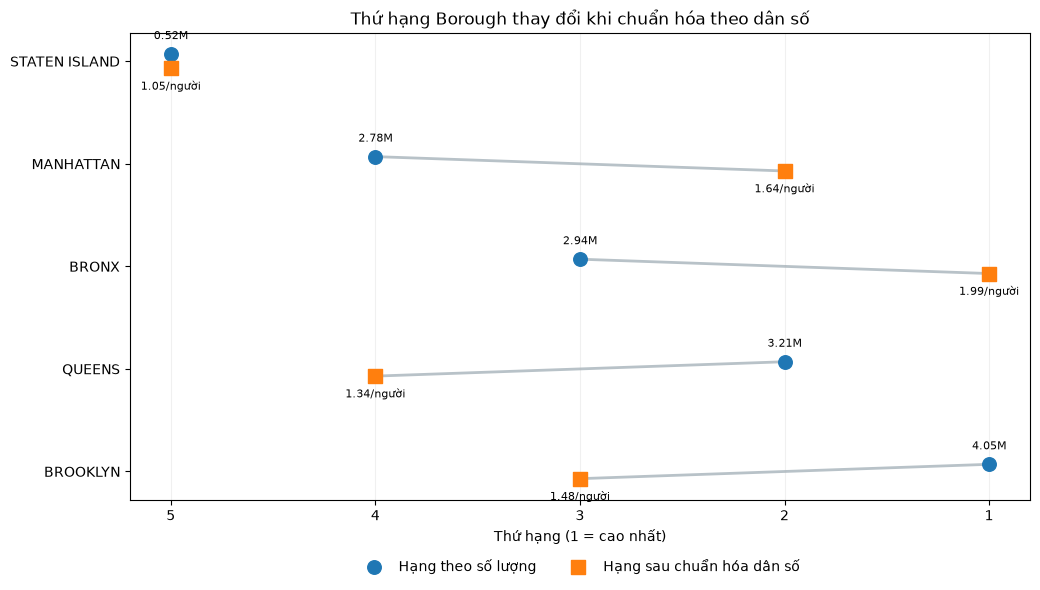

Saved: d:\nyc311_analysis\outputs\charts\borough_rank_dumbbell.png


In [79]:
fig, ax = plt.subplots(figsize=(10.5, 6))

y = np.arange(len(borough_rank))
y_abs = y + 0.07
y_norm = y - 0.07

for i, row in borough_rank.iterrows():
    ax.plot(
        [row["absolute_rank"], row["normalized_rank"]],
        [y_abs[i], y_norm[i]],
        color="#B8C2C8",
        linewidth=2,
        zorder=1,
    )

ax.scatter(
    borough_rank["absolute_rank"],
    y_abs,
    s=95,
    label="Hạng theo số lượng",
    zorder=3,
)

ax.scatter(
    borough_rank["normalized_rank"],
    y_norm,
    s=95,
    marker="s",
    label="Hạng sau chuẩn hóa dân số",
    zorder=3,
)

for i, row in borough_rank.iterrows():
    ax.text(
        row["absolute_rank"],
        y_abs[i] + 0.12,
        f"{row['requests']/1_000_000:.2f}M",
        ha="center",
        va="bottom",
        fontsize=8,
    )
    ax.text(
        row["normalized_rank"],
        y_norm[i] - 0.12,
        f"{row['requests_per_resident_4y']:.2f}/người",
        ha="center",
        va="top",
        fontsize=8,
    )

ax.set_yticks(y)
ax.set_yticklabels(borough_rank["borough"])
ax.set_xticks(range(1, 6))
ax.invert_xaxis()
ax.set_xlabel("Thứ hạng (1 = cao nhất)")
ax.set_ylabel("")
ax.set_title("Thứ hạng Borough thay đổi khi chuẩn hóa theo dân số")
ax.grid(axis="x", alpha=0.18)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=False,
)

plt.tight_layout()

BOROUGH_RANK_CHART = CHART_DIR / "borough_rank_dumbbell.png"
fig.savefig(BOROUGH_RANK_CHART, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", BOROUGH_RANK_CHART)

## 8.5 Community Board — count và tỷ lệ trên 1.000 dân

Hai bản đồ trả lời hai câu hỏi khác nhau: **count** cho biết workload tuyệt đối, còn **request/1.000 dân** dùng để so tương đối giữa các Community District có quy mô dân số khác nhau. Cả hai dùng cùng bảng màu tuần tự nhưng thang số độc lập vì đơn vị khác nhau.

In [80]:
CD_POP_FILE = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "community_district_population_2020.csv"
)

if not CD_POP_FILE.exists():
    raise FileNotFoundError(
        "Missing community_district_population_2020.csv. "
        "Copy the supplied CSV into data/external/ first."
    )

cd_population = pd.read_csv(CD_POP_FILE)

assert len(cd_population) == 59
assert cd_population["boro_cd"].nunique() == 59
assert int(cd_population["population_2020"].sum()) == 8_803_220

community_board_rate = (
    community_board_requests
    .merge(
        cd_population[["boro_cd", "population_2020"]],
        on="boro_cd",
        how="left",
        validate="one_to_one",
    )
)

if community_board_rate["population_2020"].isna().any():
    missing_codes = community_board_rate.loc[
        community_board_rate["population_2020"].isna(),
        "boro_cd",
    ].tolist()
    raise ValueError(f"Population missing for boro_cd: {missing_codes}")

community_board_rate["requests_per_1000"] = (
    community_board_rate["requests"]
    / community_board_rate["population_2020"]
    * 1000
)

community_board_rate["count_rank"] = (
    community_board_rate["requests"]
    .rank(method="min", ascending=False)
    .astype(int)
)
community_board_rate["rate_rank"] = (
    community_board_rate["requests_per_1000"]
    .rank(method="min", ascending=False)
    .astype(int)
)
community_board_rate["rank_change"] = (
    community_board_rate["count_rank"]
    - community_board_rate["rate_rank"]
)

CB_RATE_FILE = TABLE_DIR / "community_board_per_capita.parquet"
community_board_rate.to_parquet(CB_RATE_FILE, index=False)

print("Top 3 Community Board theo số yêu cầu / 1.000 dân")
display(
    community_board_rate
    .nlargest(3, "requests_per_1000")[
        [
            "community_board",
            "board_borough",
            "requests",
            "population_2020",
            "requests_per_1000",
            "count_rank",
            "rate_rank",
            "rank_change",
        ]
    ]
    .round({"requests_per_1000": 1})
)

print("Các Community Board thay đổi thứ hạng nhiều nhất sau chuẩn hóa")
display(
    community_board_rate
    .assign(abs_rank_change=lambda x: x["rank_change"].abs())
    .nlargest(10, "abs_rank_change")[
        [
            "community_board",
            "board_borough",
            "count_rank",
            "rate_rank",
            "rank_change",
            "requests_per_1000",
        ]
    ]
    .round({"requests_per_1000": 1})
)

Top 3 Community Board theo số yêu cầu / 1.000 dân


,community_board,board_borough,requests,population_2020,requests_per_1000,count_rank,rate_rank,rank_change
24,05 MANHATTAN,MANHATTAN,217001,63600,3412.0,25,1,24
0,12 BRONX,BRONX,554136,163489,3389.4,1,2,-1
9,10 MANHATTAN,MANHATTAN,308950,130440,2368.5,10,3,7


Các Community Board thay đổi thứ hạng nhiều nhất sau chuẩn hóa


,community_board,board_borough,count_rank,rate_rank,rank_change,requests_per_1000
58,02 BRONX,BRONX,59,15,44,1870.1
10,07 QUEENS,QUEENS,11,49,-38,1065.7
45,02 MANHATTAN,MANHATTAN,46,11,35,1951.2
7,12 QUEENS,QUEENS,8,42,-34,1211.2
41,06 BRONX,BRONX,42,9,33,2069.9
44,03 BRONX,BRONX,45,12,33,1927.7
13,07 MANHATTAN,MANHATTAN,14,41,-27,1226.9
47,01 BRONX,BRONX,48,23,25,1650.4
24,05 MANHATTAN,MANHATTAN,25,1,24,3412.0
39,09 BROOKLYN,BROOKLYN,40,16,24,1839.0


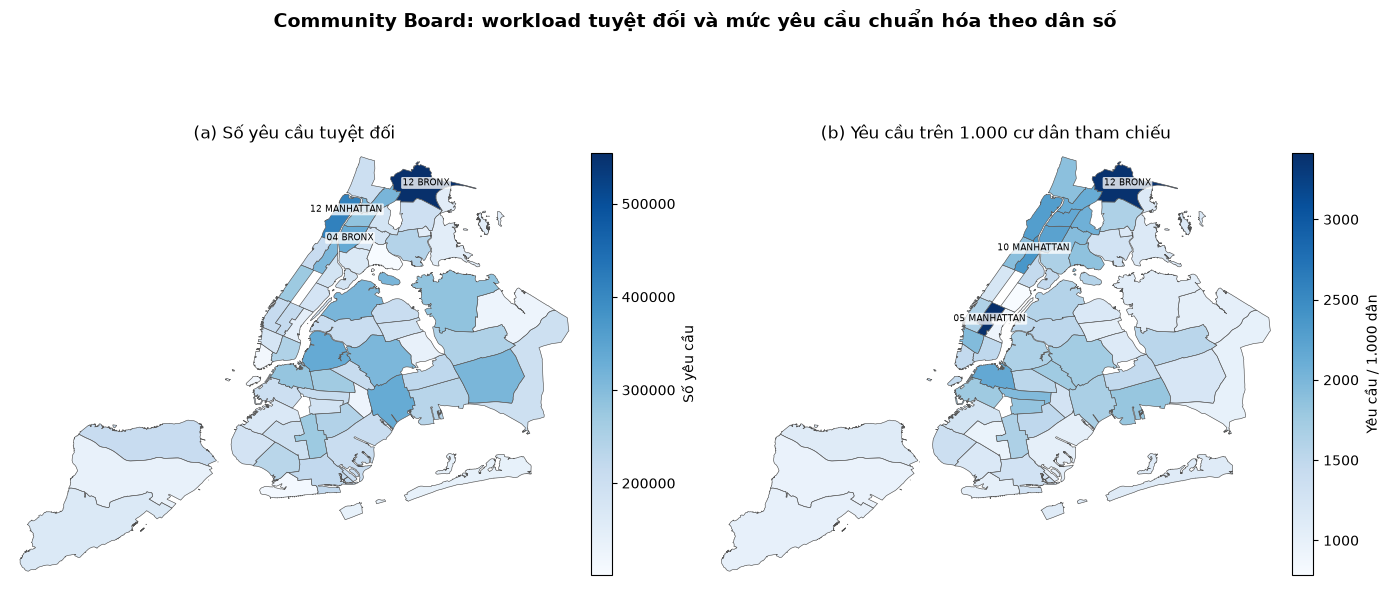

Saved: d:\nyc311_analysis\outputs\charts\community_board_count_vs_percapita.png


In [81]:
# Tạo hai choropleth tĩnh cạnh nhau bằng Matplotlib + GeoJSON.
# Không cần GeoPandas và không có Plotly toolbar.
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

cb_values = community_board_rate.copy()
cb_values["boro_cd"] = cb_values["boro_cd"].astype(int)

value_lookup_count = cb_values.set_index("boro_cd")["requests"].to_dict()
value_lookup_rate = cb_values.set_index("boro_cd")["requests_per_1000"].to_dict()
name_lookup = cb_values.set_index("boro_cd")["community_board"].to_dict()

def _extract_polygon_rings(geometry):
    """Yield exterior rings from Polygon or MultiPolygon GeoJSON geometry."""
    if geometry is None:
        return
    gtype = geometry.get("type")
    coords = geometry.get("coordinates", [])

    if gtype == "Polygon":
        if coords:
            yield coords[0]
    elif gtype == "MultiPolygon":
        for poly in coords:
            if poly:
                yield poly[0]

def _feature_boro_cd(feature):
    props = feature.get("properties", {})
    candidates = [
        props.get("boro_cd"),
        props.get("BoroCD"),
        props.get("borocd"),
        props.get("boro_cd_1"),
    ]
    for value in candidates:
        if value is not None:
            try:
                return int(value)
            except Exception:
                pass
    return None

features_with_code = []
for feature in community_board_geojson["features"]:
    code = _feature_boro_cd(feature)
    if code is not None and code in value_lookup_count:
        features_with_code.append((feature, code))

if len(features_with_code) < 50:
    raise ValueError(
        f"Chỉ ghép được {len(features_with_code)} Community District từ GeoJSON. "
        "Kiểm tra tên trường boro_cd/BoroCD trong properties."
    )

def _plot_geojson_choropleth(
    ax,
    value_lookup,
    title,
    cbar_label,
    label_codes=None,
):
    vals = [value_lookup[code] for _, code in features_with_code]
    norm = Normalize(vmin=min(vals), vmax=max(vals))
    cmap = plt.get_cmap("Blues")

    # Community District boundaries
    for feature, code in features_with_code:
        facecolor = cmap(norm(value_lookup[code]))
        for ring in _extract_polygon_rings(feature.get("geometry")):
            xy = np.asarray(ring, dtype=float)
            patch = MplPolygon(
                xy,
                closed=True,
                facecolor=facecolor,
                edgecolor="#666666",
                linewidth=0.45,
            )
            ax.add_patch(patch)

    # Borough boundaries: draw a thicker outline around district edges by
    # grouping features through first digit of boro_cd. We cannot dissolve
    # polygons without GeoPandas, so use a second pass with slightly thicker
    # outlines. This still makes borough separations visually clearer.
    for feature, code in features_with_code:
        for ring in _extract_polygon_rings(feature.get("geometry")):
            xy = np.asarray(ring, dtype=float)
            ax.plot(
                xy[:, 0],
                xy[:, 1],
                color="#303030",
                linewidth=0.15,
                alpha=0.45,
            )

    # Labels for selected Community Boards using polygon representative centroid.
    if label_codes:
        for feature, code in features_with_code:
            if code not in label_codes:
                continue

            rings = list(_extract_polygon_rings(feature.get("geometry")))
            if not rings:
                continue

            # Choose largest exterior ring and use its mean coordinate as a
            # lightweight label position. Good enough for report annotation.
            ring = max(rings, key=lambda r: len(r))
            xy = np.asarray(ring, dtype=float)
            x, y = xy[:, 0].mean(), xy[:, 1].mean()

            ax.text(
                x,
                y,
                name_lookup.get(code, str(code)),
                fontsize=6.5,
                ha="center",
                va="center",
                bbox={
                    "boxstyle": "round,pad=0.15",
                    "facecolor": "white",
                    "alpha": 0.78,
                    "edgecolor": "none",
                },
            )

    all_xy = []
    for feature, _ in features_with_code:
        for ring in _extract_polygon_rings(feature.get("geometry")):
            all_xy.extend(ring)

    all_xy = np.asarray(all_xy, dtype=float)
    ax.set_xlim(all_xy[:, 0].min() - 0.01, all_xy[:, 0].max() + 0.01)
    ax.set_ylim(all_xy[:, 1].min() - 0.01, all_xy[:, 1].max() + 0.01)
    ax.set_aspect("equal", adjustable="box")
    ax.set_axis_off()
    ax.set_title(title)

    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label(cbar_label)

top_count_codes = set(
    community_board_rate.nlargest(3, "requests")["boro_cd"].astype(int)
)
top_rate_codes = set(
    community_board_rate.nlargest(3, "requests_per_1000")["boro_cd"].astype(int)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

_plot_geojson_choropleth(
    axes[0],
    value_lookup_count,
    "(a) Số yêu cầu tuyệt đối",
    "Số yêu cầu",
    label_codes=top_count_codes,
)

_plot_geojson_choropleth(
    axes[1],
    value_lookup_rate,
    "(b) Yêu cầu trên 1.000 cư dân tham chiếu",
    "Yêu cầu / 1.000 dân",
    label_codes=top_rate_codes,
)

fig.suptitle(
    "Community Board: workload tuyệt đối và mức yêu cầu chuẩn hóa theo dân số",
    fontsize=14,
    fontweight="bold",
)

plt.tight_layout()

CB_COMPARE_MAP = CHART_DIR / "community_board_count_vs_percapita.png"
fig.savefig(CB_COMPARE_MAP, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", CB_COMPARE_MAP)

**Cách đọc để viết báo cáo.** Nêu cụ thể Top 3 Community Board theo tỷ lệ và mức thay đổi thứ hạng so với count. Nếu một khu Manhattan có tỷ lệ rất cao do mẫu số dân cư nhỏ, chỉ mô tả đó là tín hiệu cần kiểm tra. Không suy đoán về dân số ban ngày nếu chưa có dữ liệu daytime population.

## 8.6 Checklist bằng chứng cần lấy sang báo cáo

Sau khi **Restart Kernel → Run All**, ưu tiên lấy các output sau:

- `complaint_delta_2022_2025.png`
- `complaint_seasonality_small_multiples.png`
- `complaint_weekday_hour_heatmaps.png`
- `borough_complaint_per_1000_heatmap.png`
- `borough_rank_dumbbell.png`
- `community_board_count_vs_percapita.png`
- `complaint_closure_median_p90.png`
- `agency_complaint_mix.png`
- `closure_overall_summary_final.csv`

Các output này đủ để vá các lỗ hổng chính của lập luận. Không cần mở thêm nhánh descriptor hoặc benchmark nếu báo cáo không đặt thêm câu hỏi nghiên cứu tương ứng.